# Actividades 5 y 6. Modelado avanzado, clustering, optimización e interpretabilidad

## Proyecto Integrador, Fase 3: modelos de regresión, clasificación y segmentación del rendimiento académico en lengua portuguesa

Andrés Felipe Ricaurte Cortés

Maestría en Inteligencia Artificial
Universidad de La Salle, Bogotá, Colombia
Asignatura: Ciencia de Datos, Grupo 2

Noviembre de 2026

## Contenido

1. Introducción
2. Marco conceptual: modelos, validación y métricas
3. Preparación del entorno, concordancia con la Fase 2 y protocolo de evaluación
4. Modelos de regresión
5. Modelos de clasificación
6. Perceptrón multicapa en PyTorch
7. Selección final y evaluación en el conjunto de prueba
8. Interpretabilidad
9. Aprendizaje no supervisado: segmentación de estudiantes
10. Verificación de objetivos y conclusiones
11. Referencias

## 1. Introducción

Este cuaderno corresponde a la tercera fase del Proyecto Integrador (Actividades 5 y 6). Se usan los datos que quedaron preparados en la Fase 2 (data/processed/student_por_fase2.csv), con la misma partición de 454 estudiantes para entrenamiento, 97 para validación y 98 para prueba, y las mismas variables, el mismo preprocesamiento y los mismos modelos base. La idea es responder con modelos más elaborados lo que quedó planteado: si se puede predecir la nota final y la aprobación mejor que con los modelos base, qué variables pesan más y qué perfiles de estudiantes se pueden distinguir.

En la Fase 2 se vio que casi todo el poder predictivo viene de G2 y que el escenario sin notas parciales, que es el útil para intervenir temprano, es el más difícil. Por eso todo el trabajo supervisado se repite en tres escenarios: sin notas, con la nota del primer periodo (G1) y con G1 y G2. El escenario intermedio no estaba en la Fase 2, pero es razonable desde el punto de vista práctico: después del primer periodo la escuela ya tiene G1 y todavía queda tiempo para actuar, mientras que G2 llega cuando el año va más avanzado.

El trabajo se divide en cinco bloques: regresión (modelos lineales regularizados y de ensambles), clasificación (regresión logística, SVM, Random Forest y XGBoost), un perceptrón multicapa en PyTorch para ambas tareas, la evaluación final en el conjunto de prueba con su análisis de interpretabilidad, y el aprendizaje no supervisado con K-Means, DBSCAN y clustering jerárquico. Después de cada resultado importante se agrega un análisis, porque lo que interesa es entender los números y no solo reportarlos.

## 2. Marco conceptual: modelos, validación y métricas

### 2.1 Modelos de regresión y clasificación

Los modelos lineales regularizados agregan una penalización al tamaño de los coeficientes para controlar el sobreajuste cuando hay muchas variables y algunas están correlacionadas, como ocurre aquí con las variables derivadas. Ridge penaliza la suma de los cuadrados de los coeficientes (Hoerl y Kennard, 1970), Lasso penaliza la suma de sus valores absolutos y puede llevar algunos a cero (Tibshirani, 1996) y ElasticNet combina ambas penalizaciones (Zou y Hastie, 2005). La intensidad de la penalización se llama alpha (en la regresión logística se usa su inverso, C) y se elige por validación cruzada.

Random Forest promedia muchos árboles de decisión entrenados con muestras aleatorias de los datos y de las variables, lo que reduce la varianza de un árbol individual (Breiman, 2001). XGBoost, en cambio, construye los árboles uno tras otro, de modo que cada uno corrige los errores de los anteriores (Chen y Guestrin, 2016). La máquina de soporte vectorial con núcleo gaussiano busca la frontera que separa las clases con mayor margen en un espacio transformado (Cortes y Vapnik, 1995). El perceptrón multicapa es una red de capas lineales con funciones de activación no lineales, entrenada por descenso de gradiente; aquí se usa ReLU, dropout para regularizar y el optimizador AdamW (Srivastava et al., 2014; Loshchilov y Hutter, 2019), implementado en PyTorch (Paszke et al., 2019).

### 2.2 Validación cruzada y selección de hiperparámetros

Como la validación tiene solo 97 estudiantes y 15 reprobados, una sola partición da métricas ruidosas. Por eso los hiperparámetros se eligen con validación cruzada de cinco pliegues sobre el conjunto de entrenamiento (estratificada en clasificación, y repetida dos veces para que sea más estable). Cuando el espacio de búsqueda es grande se usa búsqueda aleatoria, que suele ser más eficiente que una cuadrícula completa (Bergstra y Bengio, 2012). El preprocesamiento (imputación, codificación y escalamiento) va dentro del pipeline, así que se reajusta en cada pliegue y no hay fuga de datos, como se justificó en la Fase 2.

### 2.3 Métricas

En regresión se reportan R², RMSE y MAE. En clasificación, con la clase positiva reprobado, se reportan exactitud, precisión, recall, F1 y el área bajo la curva ROC (AUC). Como la clase positiva es minoritaria, se agrega la precisión promedio (AP), que resume la curva de precisión contra recall y penaliza más los falsos positivos que el AUC; es la métrica que se usa para elegir hiperparámetros y comparar modelos. El umbral de decisión por defecto de 0,5 no tiene por qué ser el mejor para el F1, así que más adelante se ajusta con predicciones fuera de muestra del entrenamiento.

### 2.4 Aprendizaje no supervisado

K-Means agrupa a los estudiantes alrededor de K centroides minimizando la distancia interna de cada grupo (Lloyd, 1982). El número de grupos se decide con dos criterios: el método del codo, que mira la inercia (suma de distancias al cuadrado al centroide) en función de K, y el coeficiente de silueta, que para cada punto compara la distancia media a su grupo (a) con la distancia media al grupo más cercano (b), $s=(b-a)/\max(a,b)$, y va de -1 a 1 (Rousseeuw, 1987). Como segundo algoritmo se usan DBSCAN, que forma grupos por densidad y marca como ruido a los puntos aislados (Ester et al., 1996), y el clustering jerárquico aglomerativo con enlace de Ward (Ward, 1963).

### 2.5 Interpretabilidad

Los valores SHAP reparten, para cada predicción, la contribución de cada variable al resultado, a partir de la teoría de juegos (Lundberg y Lee, 2017). La importancia por permutación mide cuánto empeora una métrica cuando se desordenan los valores de una variable, y sirve con cualquier modelo (Breiman, 2001). Se usan ambas porque se complementan: SHAP explica un modelo de árboles en detalle y la permutación compara variables de forma más general.

## 3. Preparación del entorno, concordancia con la Fase 2 y protocolo de evaluación

Se cargan las mismas librerías, el estilo gráfico y la paleta de las fases anteriores, más PyTorch, XGBoost, SHAP e imbalanced-learn. Los datos se leen del archivo que dejó la Fase 2 y se verifica que la partición y las cifras coincidan con las de ese cuaderno. La celda incluye una variable que permite correr una versión rápida con menos iteraciones para depurar; con la configuración por defecto se ejecuta todo.

In [1]:
import warnings
warnings.filterwarnings("ignore")

import os, json, time, joblib
import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
import sklearn, torch, torch.nn as nn, xgboost, shap
from scipy import stats
from scipy.cluster.hierarchy import linkage, dendrogram

from sklearn.model_selection import (StratifiedKFold, KFold, RepeatedStratifiedKFold, GridSearchCV,
                                     RandomizedSearchCV, cross_val_predict, cross_validate)
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.base import clone
from sklearn.linear_model import Ridge, Lasso, ElasticNet, LinearRegression, LogisticRegression
from sklearn.ensemble import RandomForestRegressor, RandomForestClassifier
from sklearn.svm import SVC
from xgboost import XGBRegressor, XGBClassifier
from sklearn.cluster import KMeans, DBSCAN, AgglomerativeClustering
from sklearn.decomposition import PCA
from sklearn.neighbors import NearestNeighbors
from sklearn.inspection import permutation_importance
from sklearn.metrics import (r2_score, mean_squared_error, mean_absolute_error, accuracy_score, precision_score, recall_score,
                             f1_score, roc_auc_score, average_precision_score, roc_curve, confusion_matrix, make_scorer,
                             silhouette_score, davies_bouldin_score, adjusted_rand_score)
from imblearn.pipeline import Pipeline as ImbPipeline
from imblearn.over_sampling import SMOTE

plt.rcParams.update({
    "figure.dpi": 110, "savefig.dpi": 150, "font.size": 10,
    "axes.titlesize": 11, "axes.titleweight": "bold", "axes.titlelocation": "left",
    "axes.labelsize": 10, "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": False, "legend.frameon": False,
})
AZUL, NARANJA, VERDE, AMARILLO, CELESTE, GRIS = "#0072B2", "#D55E00", "#009E73", "#E69F00", "#56B4E9", "#B0B0B0"
SEMILLA = 42
torch.set_num_threads(1)

# Con la variable de entorno FASE3_RAPIDO=1 se corre una versión reducida, solo para depurar
RAPIDO = os.environ.get("FASE3_RAPIDO") == "1"
N_ITER = 3 if RAPIDO else 14        # configuraciones evaluadas en la búsqueda aleatoria
REPETICIONES = 1 if RAPIDO else 2   # repeticiones de la validación cruzada en clasificación
N_ARBOLES = 60 if RAPIDO else 300
EPOCAS = 25 if RAPIDO else 300
N_BOOT = 100 if RAPIDO else 1000

RUTA = "data/processed/student_por_fase2.csv"
if not os.path.exists(RUTA):
    raise FileNotFoundError("Falta data/processed/student_por_fase2.csv: se genera al ejecutar el cuaderno de la Fase 2.")
df = pd.read_csv(RUTA, index_col="fila")
config = json.load(open("data/processed/config_fase2.json"))
cols_completo, cols_sin_notas, nominales = config["cols_completo"], config["cols_sin_notas"], config["nominales"]
ordinales = ["Medu", "Fedu", "traveltime", "studytime", "famrel", "freetime", "goout", "Dalc", "Walc", "health"]
assert config["semilla"] == SEMILLA

# Verificación de concordancia con la Fase 2
idx = {p: df.index[df["particion"] == p] for p in ["entrenamiento", "validación", "prueba"]}
assert [len(idx[p]) for p in idx] == [454, 97, 98]
assert [int((df.loc[idx[p], "aprobado"] == 0).sum()) for p in idx] == [70, 15, 15]
assert [int((df.loc[idx[p], "G3"] == 0).sum()) for p in idx] == [8, 5, 2]
assert df["G1"].isna().sum() == 1 and len(nominales) == 17
print("Particiones (entrenamiento, validación, prueba):", [len(idx[p]) for p in idx])
print("Reprobados por partición:", [int((df.loc[idx[p], 'aprobado'] == 0).sum()) for p in idx])
print("Variables numéricas del conjunto completo:", len(cols_completo), "| sin notas:", len(cols_sin_notas), "| categóricas:", len(nominales))
print("scikit-learn", sklearn.__version__, "| PyTorch", torch.__version__, "| XGBoost", xgboost.__version__, "| SHAP", shap.__version__)
print("Modo rápido:", RAPIDO)

Particiones (entrenamiento, validación, prueba): [454, 97, 98]
Reprobados por partición: [70, 15, 15]
Variables numéricas del conjunto completo: 20 | sin notas: 17 | categóricas: 17
scikit-learn 1.9.1 | PyTorch 2.15.0+cu132 | XGBoost 3.4.1 | SHAP 0.54.1
Modo rápido: False


Las verificaciones pasan: la partición es la misma de la Fase 2 (454, 97 y 98 estudiantes; 70, 15 y 15 reprobados). A continuación se reconstruyen el preprocesador de la Fase 2 y las funciones de apoyo, y se definen los tres escenarios de variables.

In [2]:
def construir_preprocesador(num_cols, cat_cols=nominales):
    num = Pipeline([("imputador", SimpleImputer(strategy="median")), ("escalador", StandardScaler())])
    cat = Pipeline([("imputador", SimpleImputer(strategy="most_frequent")),
                    ("onehot", OneHotEncoder(drop="if_binary", handle_unknown="ignore", sparse_output=False))])
    return ColumnTransformer([("num", num, num_cols), ("cat", cat, cat_cols)])

ESC = {"Sin notas": cols_sin_notas, "Con G1": cols_sin_notas + ["G1"], "Con G1 y G2": cols_completo}

def obtener(tarea, partes, cols):
    """Devuelve X, y para una tarea ('reg' o 'clf') y una o varias particiones. En regresión se excluyen los ceros de G3."""
    d = df.loc[np.concatenate([idx[p] for p in partes])]
    if tarea == "reg":
        d = d[d["G3"] > 0]
    y = d["G3"] if tarea == "reg" else 1 - d["aprobado"]    # clasificación: 1 = reprobado
    return d[cols], y

def rmse(y, p): return float(np.sqrt(mean_squared_error(y, p)))
def met_reg(y, p): return {"R2": r2_score(y, p), "RMSE": rmse(y, p), "MAE": mean_absolute_error(y, p)}
def met_clf(y, proba, umbral=0.5):
    pred = (np.asarray(proba) >= umbral).astype(int)
    return {"Exactitud": accuracy_score(y, pred), "Precisión": precision_score(y, pred, zero_division=0),
            "Recall": recall_score(y, pred, zero_division=0), "F1": f1_score(y, pred, zero_division=0),
            "AUC": roc_auc_score(y, proba), "AP": average_precision_score(y, proba)}
def corto(p):
    return ", ".join(f"{k.split('__')[-1]}={v:.3g}" if isinstance(v, (int, float, np.floating, np.integer)) else f"{k.split('__')[-1]}={v}" for k, v in p.items())

# Modelos base de la Fase 2 (y su equivalente para el escenario con G1)
BASE_REG = {"Sin notas": "failures", "Con G1": "G1", "Con G1 y G2": "G2"}
BASE_CLF = {"Con G1": "G1", "Con G1 y G2": "G2"}
LR_BASE = lambda: LogisticRegression(class_weight="balanced", max_iter=2000, random_state=SEMILLA)
def modelo_base(tarea, esc):
    if tarea == "reg":
        c = BASE_REG[esc]
        return Pipeline([("imp", SimpleImputer(strategy="median")), ("m", LinearRegression())]), [c]
    if esc == "Sin notas":
        return Pipeline([("pre", construir_preprocesador(cols_sin_notas)), ("m", LR_BASE())]), cols_sin_notas + nominales
    c = BASE_CLF[esc]
    return Pipeline([("imp", SimpleImputer(strategy="median")), ("esc", StandardScaler()), ("m", LR_BASE())]), [c]

VAL, TRN, BASE_VAL = {}, {}, {}
for tarea in ["reg", "clf"]:
    for esc in ESC:
        m, cols = modelo_base(tarea, esc)
        Xa, ya = obtener(tarea, ["entrenamiento"], cols); Xv, yv = obtener(tarea, ["validación"], cols)
        m.fit(Xa, ya)
        BASE_VAL[(tarea, esc)] = met_reg(yv, m.predict(Xv)) if tarea == "reg" else met_clf(yv, m.predict_proba(Xv)[:, 1])

# Concordancia con las cifras reportadas en la Fase 2
assert abs(BASE_VAL[("reg", "Con G1 y G2")]["RMSE"] - 1.055) < 0.002 and abs(BASE_VAL[("reg", "Sin notas")]["RMSE"] - 2.636) < 0.002
assert abs(BASE_VAL[("clf", "Con G1 y G2")]["F1"] - 0.778) < 0.002 and abs(BASE_VAL[("clf", "Sin notas")]["F1"] - 0.367) < 0.002
print("Los modelos base reproducen los resultados de la Fase 2:")
print(pd.DataFrame({k: {m: v for m, v in d.items() if m in ("RMSE", "R2", "F1", "AUC")} for k, d in BASE_VAL.items()}).T.round(3))

Los modelos base reproducen los resultados de la Fase 2:
                    R2   RMSE     F1    AUC
reg Sin notas    0.117  2.636    NaN    NaN
    Con G1       0.821  1.187    NaN    NaN
    Con G1 y G2  0.858  1.055    NaN    NaN
clf Sin notas      NaN    NaN  0.367  0.726
    Con G1         NaN    NaN  0.750  0.967
    Con G1 y G2    NaN    NaN  0.778  0.977


Tabla 1. Los modelos base reproducen exactamente los resultados de la Fase 2: RMSE de 1,055 con G2 y de 2,636 sin notas en regresión, y F1 de 0,778 con G2 y de 0,367 sin notas en clasificación. Para el escenario nuevo (con G1) se calcula el equivalente: una regresión lineal simple y una logística con G1 como única variable. Fuente: elaboración propia con datos de Cortez y Silva (2008).

### 3.1 Escenarios y protocolo

| Escenario | Variables numéricas | Cuándo estaría disponible |
|---|---|---|
| Sin notas | 17 (edad, reprobaciones, ausencias en logaritmo, ordinales y derivadas) más 17 categóricas | Al inicio del año |
| Con G1 | Las anteriores más G1 | Después del primer periodo |
| Con G1 y G2 | Las de Con G1 más G2 y la tendencia entre notas | Después del segundo periodo |

Tabla 2. Escenarios de variables predictoras. Fuente: elaboración propia.

El protocolo de evaluación es el mismo en todas las tareas y se fijó antes de ver resultados:

1. Los hiperparámetros se eligen con validación cruzada de cinco pliegues sobre el entrenamiento (454 estudiantes en clasificación y 446 en regresión).
2. Con los mejores hiperparámetros se reajusta cada modelo en el entrenamiento y se compara en validación. El mejor de cada tarea y escenario se elige por RMSE en regresión y por precisión promedio (AP) en clasificación.
3. El modelo elegido se reajusta con entrenamiento y validación juntos (551 estudiantes) y se evalúa una única vez en el conjunto de prueba. Los modelos base se evalúan igual, para que la comparación sea justa.

Como en la Fase 2, la regresión usa solo estudiantes con nota final real (se excluyen los ceros), y la clasificación usa los 649 estudiantes, con reprobado como clase positiva.

## 4. Modelos de regresión

Se comparan cinco modelos: Ridge, Lasso y ElasticNet como modelos lineales regularizados, y Random Forest y XGBoost como modelos de ensambles. En los lineales se recorre una cuadrícula de valores de alpha (y de la proporción de Lasso en ElasticNet) y en los de árboles se usa búsqueda aleatoria sobre profundidad, tamaño mínimo de hoja, tasa de aprendizaje y otros parámetros. La métrica de la búsqueda es el RMSE de la validación cruzada.

In [3]:
CV_REG = KFold(n_splits=5, shuffle=True, random_state=SEMILLA)
CV_CLF = RepeatedStratifiedKFold(n_splits=5, n_repeats=REPETICIONES, random_state=SEMILLA)

def espacios_reg():
    return {
        "Ridge": (Ridge(), {"m__alpha": np.logspace(-2, 3, 30)}, "grid"),
        "Lasso": (Lasso(max_iter=50000), {"m__alpha": np.logspace(-3, 0.5, 25)}, "grid"),
        "ElasticNet": (ElasticNet(max_iter=50000), {"m__alpha": np.logspace(-3, 0.5, 10), "m__l1_ratio": [0.2, 0.5, 0.8, 0.95]}, "grid"),
        "Random Forest": (RandomForestRegressor(n_estimators=N_ARBOLES, random_state=SEMILLA, n_jobs=1),
                          {"m__max_depth": [3, 5, 8, None], "m__min_samples_leaf": [1, 3, 5, 10], "m__max_features": [0.3, 0.5, 1.0]}, "rand"),
        "XGBoost": (XGBRegressor(random_state=SEMILLA, n_jobs=1, tree_method="hist", verbosity=0),
                    {"m__n_estimators": [100, 200, 300], "m__max_depth": [2, 3, 4], "m__learning_rate": [0.02, 0.05, 0.1],
                     "m__subsample": [0.7, 1.0], "m__colsample_bytree": [0.5, 0.8, 1.0], "m__min_child_weight": [1, 3, 5],
                     "m__reg_lambda": [1, 5, 10]}, "rand"),
    }

def armar(est, esc, usar_smote=False):
    pre = construir_preprocesador(ESC[esc])
    if usar_smote:
        return ImbPipeline([("pre", pre), ("smote", SMOTE(random_state=SEMILLA)), ("m", est)])
    return Pipeline([("pre", pre), ("m", est)])

def buscar(pipe, grid, modo, X, y, cv, scoring):
    if modo == "grid":
        gs = GridSearchCV(pipe, grid, cv=cv, scoring=scoring, n_jobs=1)
    else:
        gs = RandomizedSearchCV(pipe, grid, n_iter=N_ITER, cv=cv, scoring=scoring, random_state=SEMILLA, n_jobs=1)
    return gs.fit(X, y)

R_REG = {}
t0 = time.time()
for esc in ESC:
    cols = ESC[esc] + nominales
    Xa, ya = obtener("reg", ["entrenamiento"], cols); Xv, yv = obtener("reg", ["validación"], cols)
    for nombre, (est, grid, modo) in espacios_reg().items():
        gs = buscar(armar(est, esc), grid, modo, Xa, ya, CV_REG, "neg_root_mean_squared_error")
        i = gs.best_index_
        R_REG[(esc, nombre)] = {"gs": gs, "cv_rmse": -gs.cv_results_["mean_test_score"][i], "cv_sd": gs.cv_results_["std_test_score"][i]}
        VAL[("reg", esc, nombre)] = met_reg(yv, gs.predict(Xv)); TRN[("reg", esc, nombre)] = met_reg(ya, gs.predict(Xa))
    print(f"Regresión, escenario {esc}: listo ({time.time() - t0:.0f} s)")

filas = []
for esc in ESC:
    cols_b = modelo_base("reg", esc)[1]
    m, _ = modelo_base("reg", esc); Xa, ya = obtener("reg", ["entrenamiento"], cols_b); m.fit(Xa, ya)
    filas.append({"Escenario": esc, "Modelo": "Base (lineal simple: " + cols_b[0] + ")", "RMSE CV": np.nan, "RMSE entren.": rmse(ya, m.predict(Xa)),
                  "RMSE valid.": BASE_VAL[("reg", esc)]["RMSE"], "R2 valid.": BASE_VAL[("reg", esc)]["R2"], "MAE valid.": BASE_VAL[("reg", esc)]["MAE"], "Hiperparámetros": "-"})
    for nombre in espacios_reg():
        r = R_REG[(esc, nombre)]
        filas.append({"Escenario": esc, "Modelo": nombre, "RMSE CV": r["cv_rmse"], "RMSE entren.": TRN[("reg", esc, nombre)]["RMSE"],
                      "RMSE valid.": VAL[("reg", esc, nombre)]["RMSE"], "R2 valid.": VAL[("reg", esc, nombre)]["R2"],
                      "MAE valid.": VAL[("reg", esc, nombre)]["MAE"], "Hiperparámetros": corto(r["gs"].best_params_)})
tabla_reg = pd.DataFrame(filas).set_index(["Escenario", "Modelo"])
tabla_reg.round(3)

Regresión, escenario Sin notas: listo (40 s)


Regresión, escenario Con G1: listo (80 s)


Regresión, escenario Con G1 y G2: listo (119 s)


RMSE CV  RMSE entren.  \
Escenario   Modelo                                                  
Sin notas   Base (lineal simple: failures)      NaN         2.454   
            Ridge                             2.203         2.055   
            Lasso                             2.190         2.064   
            ElasticNet                        2.191         2.056   
            Random Forest                     2.187         1.385   
            XGBoost                           2.163         1.714   
Con G1      Base (lineal simple: G1)            NaN         1.317   
            Ridge                             1.281         1.172   
            Lasso                             1.273         1.178   
            ElasticNet                        1.271         1.188   
            Random Forest                     1.340         0.496   
            XGBoost                           1.318         0.846   
Con G1 y G2 Base (lineal simple: G2)            NaN         0.969   
            Ridge                             0.948         0.883   
            Lasso                             0.921         0.908   
            ElasticNet                        0.922         0.905   
            Random Forest                     0.962         0.363   
            XGBoost                           0.952         0.630   

                                            RMSE valid.  R2 valid.  \
Escenario   Modelo                                                   
Sin notas   Base (lineal simple: failures)        2.636      0.117   
            Ridge                                 2.332      0.308   
            Lasso                                 2.374      0.283   
            ElasticNet                            2.376      0.282   
            Random Forest                         2.262      0.349   
            XGBoost                               2.234      0.366   
Con G1      Base (lineal simple: G1)              1.187      0.821   
            Ridge                                 1.283      0.791   
            Lasso                                 1.255      0.800   
            ElasticNet                            1.242      0.804   
            Random Forest                         1.256      0.799   
            XGBoost                               1.255      0.800   
Con G1 y G2 Base (lineal simple: G2)              1.055      0.858   
            Ridge                                 1.025      0.866   
            Lasso                                 0.999      0.873   
            ElasticNet                            1.001      0.872   
            Random Forest                         1.095      0.847   
            XGBoost                               1.062      0.857   

                                            MAE valid.  \
Escenario   Modelo                                       
Sin notas   Base (lineal simple: failures)       2.131   
            Ridge                                1.768   
            Lasso                                1.824   
            ElasticNet                           1.827   
            Random Forest                        1.688   
            XGBoost                              1.706   
Con G1      Base (lineal simple: G1)             0.896   
            Ridge                                0.963   
            Lasso                                0.924   
            ElasticNet                           0.915   
            Random Forest                        0.946   
            XGBoost                              0.933   
Con G1 y G2 Base (lineal simple: G2)             0.761   
            Ridge                                0.694   
            Lasso                                0.688   
            ElasticNet                           0.686   
            Random Forest                        0.733   
            XGBoost                              0.713   

                                                                              Hiperparámetros  
Escen

Tabla 3. Regresión de la nota final: error en validación cruzada (RMSE CV), en entrenamiento y en validación, con los hiperparámetros elegidos. El RMSE CV de los modelos base no se calcula porque no tienen hiperparámetros que elegir. Fuente: elaboración propia con datos de Cortez y Silva (2008).

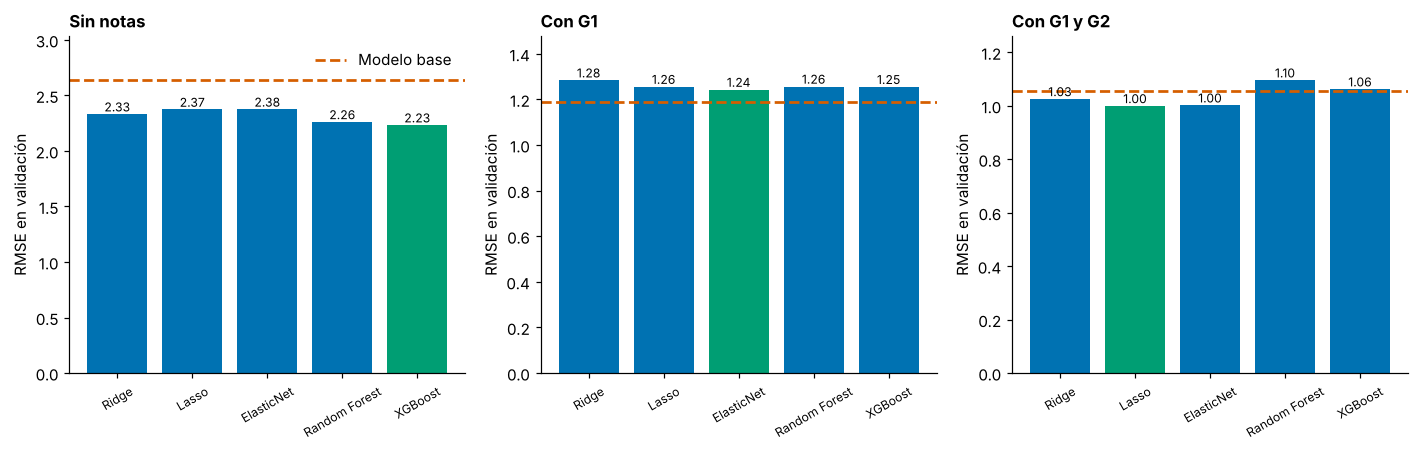

In [4]:
orden = [m for m in espacios_reg()]
fig, ejes = plt.subplots(1, 3, figsize=(13, 4.2), sharey=False)
for ax, esc in zip(ejes, ESC):
    v = [VAL[("reg", esc, m)]["RMSE"] for m in orden]
    c = [VERDE if x == min(v) else AZUL for x in v]
    ax.bar(orden, v, color=c)
    ax.axhline(BASE_VAL[("reg", esc)]["RMSE"], color=NARANJA, ls="--", lw=1.8, label="Modelo base")
    for i, x in enumerate(v): ax.text(i, x + 0.01 * max(v), f"{x:.2f}", ha="center", fontsize=8)
    ax.set_title(esc); ax.set_ylabel("RMSE en validación"); ax.tick_params(axis="x", rotation=30, labelsize=8)
    ax.set_ylim(0, max(max(v), BASE_VAL[("reg", esc)]["RMSE"]) * 1.15)
ejes[0].legend()
fig.tight_layout(); plt.show()

Figura 1. RMSE en validación de los cinco modelos de regresión en cada escenario; en verde el mejor y la línea naranja es el modelo base. Fuente: elaboración propia con datos de Cortez y Silva (2008).

Análisis. Los resultados dependen mucho del escenario. Sin notas, el modelo base (reprobaciones previas) tiene un RMSE de 2,64 en validación y un R² de 0,12, y todos los modelos lo mejoran: XGBoost llega a 2,23 (R² de 0,37), Random Forest a 2,26 y Ridge a 2,33, es decir una reducción de entre 12 % y 15 % del error y un R² que se triplica. Aquí los modelos de árboles superan a los lineales, lo que sugiere que hay interacciones entre variables (por ejemplo, entre escuela, reprobaciones y deseo de estudiar) que un modelo lineal no captura. El error en validación cruzada (RMSE de 2,16 a 2,20) es consistente con el de validación.

Con G1 ocurre lo contrario: el modelo base con G1 como única variable (RMSE de 1,19) no es superado por ningún modelo multivariable (entre 1,24 y 1,28). La diferencia es pequeña y entra en el ruido de una validación de 92 estudiantes, pero indica que agregar las demás variables no aporta información útil una vez que se conoce G1. Con G1 y G2, el mejor es Lasso con un RMSE de 1,00 y un R² de 0,87, frente a 1,06 y 0,86 del modelo base, seguido de cerca por ElasticNet y Ridge. Los modelos lineales ganan a los de árboles, lo que es coherente con lo visto en la Fase 1: la relación entre G2 y G3 es casi una recta.

También se ve el sobreajuste de los modelos flexibles. Random Forest tiene un RMSE de 0,36 en entrenamiento y de 1,10 en validación con G1 y G2, y XGBoost pasa de 0,63 a 1,06, mientras que los lineales se mueven poco (0,91 en entrenamiento y 1,00 en validación en el caso de Lasso). Con 446 estudiantes y una señal tan lineal, los árboles memorizan ruido.

## 5. Modelos de clasificación

### 5.1 Tratamiento del desbalance

En la Fase 2 se dejó pendiente probar SMOTE (Chawla et al., 2002) contra el ajuste de pesos de clase, que se usó en los modelos base. Se hace una comparación directa con validación cruzada repetida sobre el entrenamiento, con una regresión logística y un Random Forest de configuración fija, en tres variantes: sin tratamiento, con pesos de clase y con SMOTE aplicado solo dentro de cada pliegue de entrenamiento (para que no se contamine el pliegue de evaluación). La regla para decidir se definió antes de ver los resultados: se usa SMOTE solo si mejora la precisión promedio (AP) media frente a los pesos de clase en más de 0,01; si no, se mantienen los pesos de clase, que son más simples y no generan datos sintéticos.

In [5]:
def variante(modelo, var, esc):
    if modelo == "Logística":
        mk = lambda cw: LogisticRegression(C=0.3, class_weight=cw, max_iter=5000)
    else:
        mk = lambda cw: RandomForestClassifier(n_estimators=N_ARBOLES // 2 + 50, min_samples_leaf=3, class_weight=("balanced_subsample" if cw else None), random_state=SEMILLA, n_jobs=1)
    if var == "Sin tratamiento": return armar(mk(None), esc)
    if var == "Pesos de clase": return armar(mk("balanced"), esc)
    return armar(mk(None), esc, usar_smote=True)

scoring = {"AP": "average_precision", "AUC": "roc_auc", "Recall": make_scorer(recall_score), "Precisión": make_scorer(precision_score, zero_division=0), "F1": make_scorer(f1_score)}
filas = []
for esc in ESC:
    Xa, ya = obtener("clf", ["entrenamiento"], ESC[esc] + nominales)
    for modelo in ["Logística", "Random Forest"]:
        for var in ["Sin tratamiento", "Pesos de clase", "SMOTE"]:
            r = cross_validate(variante(modelo, var, esc), Xa, ya, cv=CV_CLF, scoring=scoring, n_jobs=1)
            filas.append({"Escenario": esc, "Modelo": modelo, "Variante": var, **{k: r[f"test_{k}"].mean() for k in scoring}})
tabla_smote = pd.DataFrame(filas).set_index(["Escenario", "Modelo", "Variante"])
resumen_var = tabla_smote.groupby("Variante")[["AP", "AUC", "Recall", "Precisión", "F1"]].mean()
USAR_SMOTE = bool(resumen_var.loc["SMOTE", "AP"] - resumen_var.loc["Pesos de clase", "AP"] > 0.01)
print("Promedio por variante (sobre escenarios y modelos):")
print(resumen_var.round(3))
print("\nUsar SMOTE según la regla definida:", USAR_SMOTE)
tabla_smote.round(3)

Promedio por variante (sobre escenarios y modelos):
                    AP    AUC  Recall  Precisión     F1
Variante                                               
Pesos de clase   0.730  0.920   0.754      0.608  0.663
SMOTE            0.738  0.923   0.713      0.643  0.659
Sin tratamiento  0.743  0.925   0.482      0.765  0.567

Usar SMOTE según la regla definida: False


AP    AUC  Recall  Precisión  \
Escenario   Modelo        Variante                                           
Sin notas   Logística     Sin tratamiento  0.525  0.843   0.371      0.569   
                          Pesos de clase   0.542  0.838   0.707      0.430   
                          SMOTE            0.532  0.833   0.700      0.440   
            Random Forest Sin tratamiento  0.586  0.872   0.129      0.673   
                          Pesos de clase   0.578  0.866   0.529      0.606   
                          SMOTE            0.571  0.875   0.421      0.637   
Con G1      Logística     Sin tratamiento  0.798  0.948   0.557      0.713   
                          Pesos de clase   0.777  0.943   0.836      0.571   
                          SMOTE            0.793  0.944   0.807      0.603   
            Random Forest Sin tratamiento  0.818  0.954   0.557      0.933   
                          Pesos de clase   0.788  0.950   0.721      0.649   
                          SMOTE            0.819  0.958   0.686      0.725   
Con G1 y G2 Logística     Sin tratamiento  0.840  0.959   0.643      0.819   
                          Pesos de clase   0.821  0.954   0.907      0.630   
                          SMOTE            0.840  0.958   0.879      0.659   
            Random Forest Sin tratamiento  0.893  0.973   0.636      0.883   
                          Pesos de clase   0.877  0.970   0.821      0.765   
                          SMOTE            0.874  0.971   0.786      0.793   

                                              F1  
Escenario   Modelo        Variante                
Sin notas   Logística     Sin tratamiento  0.432  
                          Pesos de clase   0.533  
                          SMOTE            0.539  
            Random Forest Sin tratamiento  0.207  
                          Pesos de clase   0.555  
                          SMOTE            0.489  
Con G1      Logística     Sin tratamiento  0.620  
                          Pesos de clase   0.676  
                          SMOTE            0.688  
            Random Forest Sin tratamiento  0.693  
                          Pesos de clase   0.680  
                          SMOTE            0.701  
Con G1 y G2 Logística     Sin tratamiento  0.719  
                          Pesos de clase   0.743  
                          SMOTE            0.752  
            Random Forest Sin tratamiento  0.733  
                          Pesos de clase   0.788  
                          SMOTE            0.785

Tabla 4. Comparación de tratamientos del desbalance en validación cruzada sobre el entrenamiento (promedio de los pliegues). Fuente: elaboración propia con datos de Cortez y Silva (2008).

Análisis. Las tres variantes tienen una precisión promedio (AP) casi idéntica (0,743 sin tratamiento, 0,730 con pesos de clase y 0,738 con SMOTE), igual que el AUC (alrededor de 0,92). Esto indica que el tratamiento del desbalance casi no cambia la capacidad del modelo para ordenar a los estudiantes por riesgo. Lo que sí cambia es el punto de operación: sin tratamiento el recall promedio es de apenas 0,48 (se les escapa más de la mitad de los reprobados), mientras que con pesos de clase sube a 0,75 y con SMOTE a 0,71, a cambio de menos precisión. El caso extremo es Random Forest sin notas: sin tratamiento detecta solo el 13 % de los reprobados (F1 de 0,21) y con pesos de clase llega a 0,53 (F1 de 0,56). Con la regla definida de antemano (SMOTE solo si mejora el AP en más de 0,01), la diferencia frente a los pesos de clase es de 0,008, así que se mantienen los pesos de clase. La conclusión práctica es que el desbalance de 15,4 % se maneja bien con pesos y con un ajuste posterior del umbral, sin necesidad de datos sintéticos.

### 5.2 Búsqueda de hiperparámetros y comparación

Se comparan cuatro algoritmos: regresión logística regularizada (que extiende al modelo base), máquina de soporte vectorial con núcleo gaussiano, Random Forest y XGBoost. Con esto se cumple el mínimo de la guía de dos algoritmos distintos de clasificación y se agrega una referencia lineal. La búsqueda optimiza la precisión promedio en validación cruzada estratificada repetida.

In [6]:
def espacios_clf(ya):
    pos_w = float((ya == 0).sum() / (ya == 1).sum())
    cw = None if USAR_SMOTE else "balanced"
    return {
        "Logística": (LogisticRegression(class_weight=cw, max_iter=5000), {"m__C": np.logspace(-3, 2, 20)}, "grid"),
        "SVM (RBF)": (SVC(probability=True, class_weight=cw, random_state=SEMILLA),
                      {"m__C": np.logspace(-2, 2, 9), "m__gamma": list(np.logspace(-4, -0.5, 8)) + ["scale"]}, "rand"),
        "Random Forest": (RandomForestClassifier(n_estimators=N_ARBOLES, class_weight=("balanced_subsample" if cw else None), random_state=SEMILLA, n_jobs=1),
                          {"m__max_depth": [3, 5, 8, None], "m__min_samples_leaf": [1, 3, 5, 10], "m__max_features": ["sqrt", 0.3, 0.5]}, "rand"),
        "XGBoost": (XGBClassifier(scale_pos_weight=(1.0 if USAR_SMOTE else pos_w), random_state=SEMILLA, n_jobs=1, tree_method="hist", verbosity=0, eval_metric="logloss"),
                    {"m__n_estimators": [100, 200, 300], "m__max_depth": [2, 3, 4], "m__learning_rate": [0.02, 0.05, 0.1],
                     "m__subsample": [0.7, 1.0], "m__colsample_bytree": [0.5, 0.8, 1.0], "m__min_child_weight": [1, 3, 5], "m__reg_lambda": [1, 5, 10]}, "rand"),
    }

R_CLF = {}
t0 = time.time()
for esc in ESC:
    cols = ESC[esc] + nominales
    Xa, ya = obtener("clf", ["entrenamiento"], cols); Xv, yv = obtener("clf", ["validación"], cols)
    for nombre, (est, grid, modo) in espacios_clf(ya).items():
        gs = buscar(armar(est, esc, USAR_SMOTE), grid, modo, Xa, ya, CV_CLF, "average_precision")
        i = gs.best_index_
        R_CLF[(esc, nombre)] = {"gs": gs, "cv_ap": gs.cv_results_["mean_test_score"][i], "cv_sd": gs.cv_results_["std_test_score"][i]}
        VAL[("clf", esc, nombre)] = met_clf(yv, gs.predict_proba(Xv)[:, 1]); TRN[("clf", esc, nombre)] = met_clf(ya, gs.predict_proba(Xa)[:, 1])
    print(f"Clasificación, escenario {esc}: listo ({time.time() - t0:.0f} s)")

filas = []
for esc in ESC:
    b = BASE_VAL[("clf", esc)]
    filas.append({"Escenario": esc, "Modelo": "Base (logística)", "AP CV": np.nan, "AP entren.": np.nan, "AP valid.": b["AP"], "AUC valid.": b["AUC"],
                  "Precisión": b["Precisión"], "Recall": b["Recall"], "F1 valid.": b["F1"], "Hiperparámetros": "-"})
    for nombre in ["Logística", "SVM (RBF)", "Random Forest", "XGBoost"]:
        r, v = R_CLF[(esc, nombre)], VAL[("clf", esc, nombre)]
        filas.append({"Escenario": esc, "Modelo": nombre, "AP CV": r["cv_ap"], "AP entren.": TRN[("clf", esc, nombre)]["AP"], "AP valid.": v["AP"], "AUC valid.": v["AUC"],
                      "Precisión": v["Precisión"], "Recall": v["Recall"], "F1 valid.": v["F1"], "Hiperparámetros": corto(r["gs"].best_params_)})
tabla_clf = pd.DataFrame(filas).set_index(["Escenario", "Modelo"])
tabla_clf.round(3)

Clasificación, escenario Sin notas: listo (90 s)


Clasificación, escenario Con G1: listo (182 s)


Clasificación, escenario Con G1 y G2: listo (273 s)


AP CV  AP entren.  AP valid.  AUC valid.  \
Escenario   Modelo                                                       
Sin notas   Base (logística)    NaN         NaN      0.413       0.726   
            Logística         0.550       0.597      0.402       0.722   
            SVM (RBF)         0.598       0.978      0.406       0.741   
            Random Forest     0.595       1.000      0.493       0.780   
            XGBoost           0.614       0.899      0.508       0.811   
Con G1      Base (logística)    NaN         NaN      0.793       0.967   
            Logística         0.779       0.879      0.750       0.954   
            SVM (RBF)         0.772       0.957      0.716       0.950   
            Random Forest     0.824       0.926      0.644       0.943   
            XGBoost           0.821       1.000      0.602       0.935   
Con G1 y G2 Base (logística)    NaN         NaN      0.867       0.977   
            Logística         0.826       0.917      0.868       0.968   
            SVM (RBF)         0.821       0.971      0.875       0.974   
            Random Forest     0.877       0.997      0.785       0.963   
            XGBoost           0.860       0.980      0.919       0.983   

                              Precisión  Recall  F1 valid.  \
Escenario   Modelo                                           
Sin notas   Base (logística)      0.265   0.600      0.367   
            Logística             0.267   0.533      0.356   
            SVM (RBF)             0.333   0.267      0.296   
            Random Forest         0.556   0.333      0.417   
            XGBoost               0.300   0.600      0.400   
Con G1      Base (logística)      0.600   1.000      0.750   
            Logística             0.484   1.000      0.652   
            SVM (RBF)             0.714   0.667      0.690   
            Random Forest         0.600   1.000      0.750   
            XGBoost               0.682   1.000      0.811   
Con G1 y G2 Base (logística)      0.667   0.933      0.778   
            Logística             0.560   0.933      0.700   
            SVM (RBF)             0.650   0.867      0.743   
            Random Forest         0.667   0.933      0.778   
            XGBoost               0.652   1.000      0.789   

                                                                Hiperparámetros  
Escenario   Modelo                                                               
Sin notas   Base (logística)                                                  -  
            Logística                                                  C=0.0379  
            SVM (RBF)                                        gamma=0.1, C=0.316  
            Random Forest     min_samples_leaf=1, max_features=0.3, max_dept...  
            XGBoost           subsample=1, reg_lambda=5, n_estimators=300, m...  
Con G1      Base (logística)                                                  -  
            Logística                                                   C=0.234  
            SVM (RBF)                                        gamma=0.01, C=3.16  
            Random Forest     min_samples_leaf=1, max_features=0.5, max_depth=3  
            XGBoost           subsample=1, reg_lambda=1, n_estimators=300, m...  
Con G1 y G2 Base (logística)                                                  -  
            Logística                                                   C=0.127  
            SVM (RBF)                                        gamma=0.01, C=3.16  
            Random Forest     min_samples_leaf=3, max_features=sqrt, max_dep...  
            XGBoost           subsample=1, reg_lambda=5, n_estimators=300, m...

Tabla 5. Clasificación de la clase reprobado: precisión promedio (AP) en validación cruzada, entrenamiento y validación, y métricas en validación con umbral de 0,5. Fuente: elaboración propia con datos de Cortez y Silva (2008).

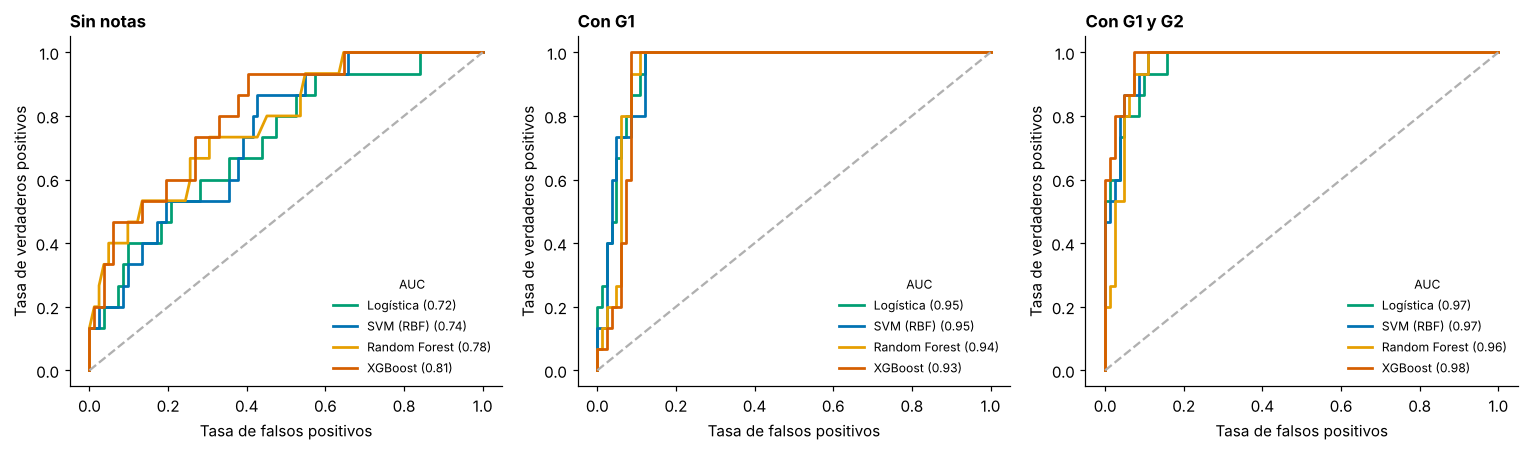

In [7]:
modelos_clf = ["Logística", "SVM (RBF)", "Random Forest", "XGBoost"]
fig, ejes = plt.subplots(1, 3, figsize=(14, 4.2))
cols_m = [VERDE, AZUL, AMARILLO, NARANJA]
for ax, esc in zip(ejes, ESC):
    Xv, yv = obtener("clf", ["validación"], ESC[esc] + nominales)
    for m, c in zip(modelos_clf, cols_m):
        fpr, tpr, _ = roc_curve(yv, R_CLF[(esc, m)]["gs"].predict_proba(Xv)[:, 1])
        ax.plot(fpr, tpr, color=c, lw=1.8, label=f"{m} ({VAL[('clf', esc, m)]['AUC']:.2f})")
    ax.plot([0, 1], [0, 1], color=GRIS, ls="--")
    ax.set_title(esc); ax.set_xlabel("Tasa de falsos positivos"); ax.set_ylabel("Tasa de verdaderos positivos"); ax.legend(fontsize=8, loc="lower right", title="AUC", title_fontsize=8)
fig.tight_layout(); plt.show()

Figura 2. Curvas ROC en validación de los cuatro algoritmos de clasificación en cada escenario. Fuente: elaboración propia con datos de Cortez y Silva (2008).

Análisis. Sin notas, que es el escenario difícil, los modelos de árboles mejoran al modelo base: en validación XGBoost alcanza una AP de 0,51 y un AUC de 0,81, y Random Forest 0,49 y 0,78, frente a 0,41 y 0,73 del base. La regresión logística y la SVM no lo superan (AP de 0,40 y 0,41). En validación cruzada los resultados van en el mismo sentido (AP de 0,61 para XGBoost y de 0,60 para Random Forest y SVM, contra 0,55 para la logística). El sobreajuste es evidente: Random Forest llega a una AP de 1,00 en entrenamiento y XGBoost de 0,90, contra 0,49 y 0,51 en validación.

Con G1 y con G1 y G2 la imagen es más ambigua. Con G1, la validación favorece a la regresión logística (AP de 0,75) y a los modelos base (0,79) por encima de Random Forest (0,64) y XGBoost (0,60), pero la validación cruzada dice lo contrario (AP de 0,82 para ambos modelos de árboles frente a 0,78 de la logística). Con G1 y G2, XGBoost obtiene la mejor AP en validación (0,92, AUC de 0,98 y F1 de 0,79), por encima del base (0,87 y 0,78), mientras que en validación cruzada el mejor es Random Forest (0,88). Que la validación y la validación cruzada discrepen es esperable cuando hay solo 15 reprobados en validación: un solo estudiante mal clasificado mueve varios puntos las métricas. Por eso, en estos dos escenarios las diferencias entre modelos no son concluyentes, y el hecho de que un modelo simple basado en la nota parcial sea tan difícil de superar confirma que la información está en G1 y G2.

## 6. Perceptrón multicapa en PyTorch

Se diseña un perceptrón multicapa con capas lineales, activación ReLU y dropout, que se usa tanto para regresión como para clasificación. En clasificación la pérdida es la entropía cruzada binaria con peso para la clase positiva (el cociente entre aprobados y reprobados del entrenamiento), el equivalente en redes a los pesos de clase. En regresión la pérdida es el error cuadrático medio sobre la nota estandarizada. Se entrena con AdamW en minilotes de 64, con parada temprana según la pérdida en validación y recuperando los pesos de la mejor época. Se prueban cuatro arquitecturas pequeñas (tamaño de capas, dropout y decaimiento de pesos), porque con 454 estudiantes una red grande sobreajustaría rápido, y se elige la de menor pérdida en validación. A diferencia de los otros modelos, aquí no hay validación cruzada: la configuración se elige con la validación, algo que conviene recordar al comparar. Se grafica la pérdida de entrenamiento y de validación por época, como pide la guía.

In [8]:
class RedMLP(nn.Module):
    def __init__(self, d, ocultas=(64, 32), p=0.3):
        super().__init__()
        capas, a = [], d
        for h in ocultas:
            capas += [nn.Linear(a, h), nn.ReLU(), nn.Dropout(p)]; a = h
        capas.append(nn.Linear(a, 1))
        self.red = nn.Sequential(*capas)
    def forward(self, x): return self.red(x).squeeze(1)

def entrenar_mlp(Xtr, ytr, Xva=None, yva=None, tarea="clf", ocultas=(64, 32), p=0.3, wd=1e-3, lr=1e-3, epocas=EPOCAS, paciencia=40, n_fijo=None):
    torch.manual_seed(SEMILLA); np.random.seed(SEMILLA)
    ytr = np.asarray(ytr, dtype=np.float32)
    mu, sd = (ytr.mean(), ytr.std()) if tarea == "reg" else (0.0, 1.0)
    Xt = torch.tensor(Xtr, dtype=torch.float32); yt = torch.tensor((ytr - mu) / sd, dtype=torch.float32)
    if tarea == "clf":
        fn = nn.BCEWithLogitsLoss(pos_weight=torch.tensor(float((ytr == 0).sum() / (ytr == 1).sum())))
    else:
        fn = nn.MSELoss()
    tiene_val = Xva is not None
    if tiene_val:
        Xv = torch.tensor(Xva, dtype=torch.float32); yv = torch.tensor((np.asarray(yva, dtype=np.float32) - mu) / sd, dtype=torch.float32)
    red = RedMLP(Xt.shape[1], ocultas, p); opt = torch.optim.AdamW(red.parameters(), lr=lr, weight_decay=wd)
    hist = {"train": [], "val": []}; mejor, mejor_ep, estado, sin_mejora = np.inf, 0, None, 0
    for ep in range(n_fijo if n_fijo else epocas):
        red.train(); perm = torch.randperm(len(Xt))
        for i in range(0, len(Xt), 64):
            b = perm[i:i + 64]; opt.zero_grad(); fn(red(Xt[b]), yt[b]).backward(); opt.step()
        red.eval()
        with torch.no_grad():
            hist["train"].append(fn(red(Xt), yt).item())
            if tiene_val:
                vl = fn(red(Xv), yv).item(); hist["val"].append(vl)
                if vl < mejor - 1e-5:
                    mejor, mejor_ep, sin_mejora = vl, ep + 1, 0
                    estado = {k: v.clone() for k, v in red.state_dict().items()}
                else:
                    sin_mejora += 1
                    if sin_mejora >= paciencia: break
    if tiene_val and estado is not None: red.load_state_dict(estado)
    red.eval()
    return {"red": red, "mu": mu, "sd": sd, "hist": hist, "mejor_ep": mejor_ep if tiene_val else n_fijo, "mejor_val": mejor, "tarea": tarea}

def predecir_mlp(m, X):
    with torch.no_grad():
        z = m["red"](torch.tensor(X, dtype=torch.float32)).numpy()
    return z * m["sd"] + m["mu"] if m["tarea"] == "reg" else 1 / (1 + np.exp(-z))

CONFIGS = [((32,), 0.1, 1e-3), ((64, 32), 0.3, 1e-3), ((64, 32), 0.3, 1e-2), ((128, 64), 0.5, 1e-2)]
MLP = {}
t0 = time.time()
for tarea in ["reg", "clf"]:
    for esc in ESC:
        cols = ESC[esc] + nominales
        Xa, ya = obtener(tarea, ["entrenamiento"], cols); Xv, yv = obtener(tarea, ["validación"], cols)
        pre = construir_preprocesador(ESC[esc]); Za = pre.fit_transform(Xa); Zv = pre.transform(Xv)
        mejor = None
        for oc, p, wd in CONFIGS:
            r = entrenar_mlp(Za, ya, Zv, yv, tarea, ocultas=oc, p=p, wd=wd)
            if mejor is None or r["mejor_val"] < mejor["mejor_val"]:
                mejor = r; mejor["config"] = (oc, p, wd)
        pred = predecir_mlp(mejor, Zv)
        VAL[(tarea, esc, "MLP (PyTorch)")] = met_reg(yv, pred) if tarea == "reg" else met_clf(yv, pred)
        MLP[(tarea, esc)] = mejor
    print(f"MLP {tarea}: listo ({time.time() - t0:.0f} s)")

filas = []
for (tarea, esc), r in MLP.items():
    v = VAL[(tarea, esc, "MLP (PyTorch)")]
    filas.append({"Tarea": "Regresión" if tarea == "reg" else "Clasificación", "Escenario": esc, "Capas ocultas": str(r["config"][0]), "Dropout": r["config"][1],
                  "Decaimiento": r["config"][2], "Mejor época": r["mejor_ep"], "Pérdida valid.": round(r["mejor_val"], 3),
                  **({"R2": v["R2"], "RMSE": v["RMSE"], "MAE": v["MAE"]} if tarea == "reg" else {"AP": v["AP"], "AUC": v["AUC"], "Recall": v["Recall"], "F1": v["F1"]})})
pd.DataFrame(filas).set_index(["Tarea", "Escenario"]).round(3)

MLP reg: listo (12 s)


MLP clf: listo (18 s)


Capas ocultas  Dropout  Decaimiento  Mejor época  \
Tarea         Escenario                                                      
Regresión     Sin notas        (64, 32)      0.3        0.001           70   
              Con G1          (128, 64)      0.5        0.010           40   
              Con G1 y G2     (128, 64)      0.5        0.010           34   
Clasificación Sin notas       (128, 64)      0.5        0.010            6   
              Con G1              (32,)      0.1        0.001          145   
              Con G1 y G2     (128, 64)      0.5        0.010           20   

                           Pérdida valid.     R2   RMSE    MAE     AP    AUC  \
Tarea         Escenario                                                        
Regresión     Sin notas             0.722  0.346  2.268  1.805    NaN    NaN   
              Con G1                0.221  0.800  1.255  0.948    NaN    NaN   
              Con G1 y G2           0.146  0.867  1.021  0.751    NaN    NaN   
Clasificación Sin notas             1.078    NaN    NaN    NaN  0.363  0.693   
              Con G1                0.428    NaN    NaN    NaN  0.717  0.951   
              Con G1 y G2           0.396    NaN    NaN    NaN  0.812  0.961   

                           Recall     F1  
Tarea         Escenario                   
Regresión     Sin notas       NaN    NaN  
              Con G1          NaN    NaN  
              Con G1 y G2     NaN    NaN  
Clasificación Sin notas     0.600  0.375  
              Con G1        1.000  0.732  
              Con G1 y G2   0.933  0.667

Tabla 6. Perceptrón multicapa: configuración elegida, mejor época y métricas en validación. Fuente: elaboración propia con datos de Cortez y Silva (2008).

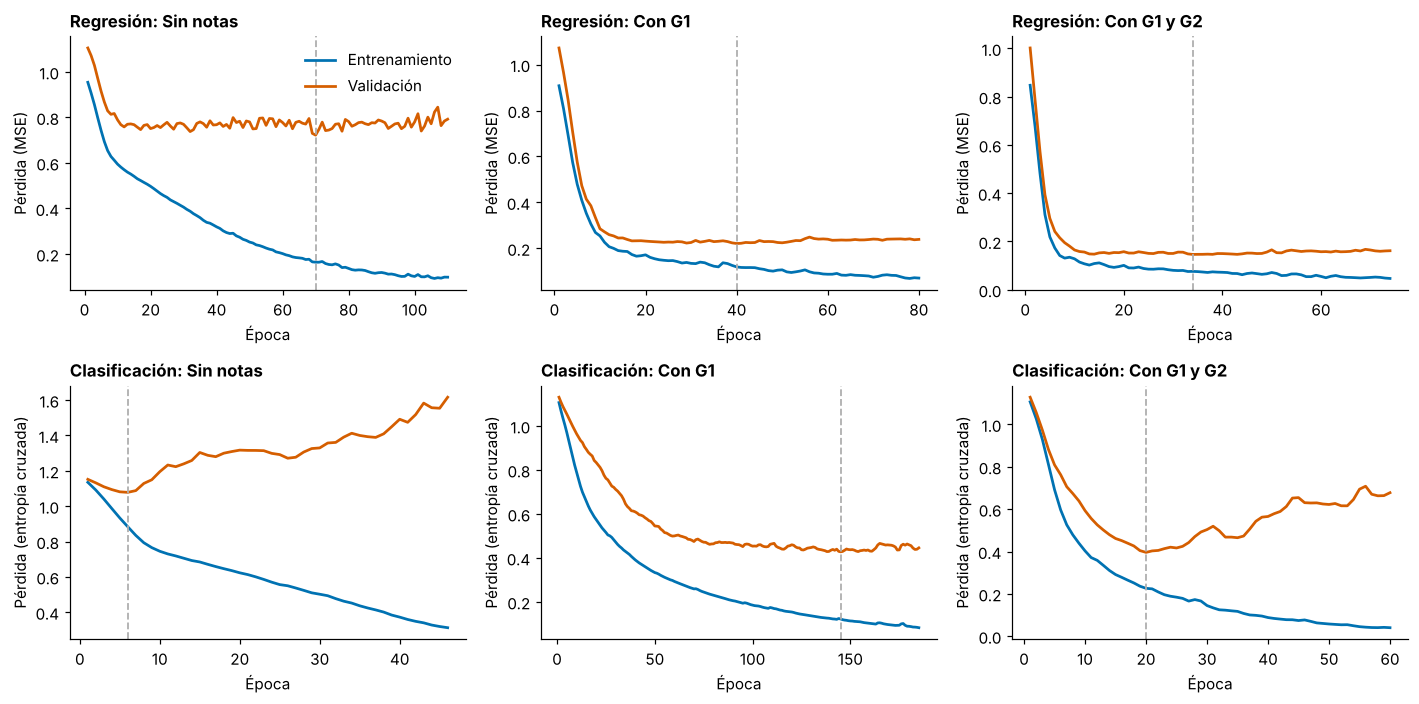

In [9]:
fig, ejes = plt.subplots(2, 3, figsize=(13, 6.5), sharex=False)
for fila, tarea in enumerate(["reg", "clf"]):
    for col, esc in enumerate(ESC):
        r = MLP[(tarea, esc)]; ax = ejes[fila, col]
        ax.plot(range(1, len(r["hist"]["train"]) + 1), r["hist"]["train"], color=AZUL, lw=1.8, label="Entrenamiento")
        ax.plot(range(1, len(r["hist"]["val"]) + 1), r["hist"]["val"], color=NARANJA, lw=1.8, label="Validación")
        ax.axvline(r["mejor_ep"], color=GRIS, ls="--", lw=1.2)
        ax.set_title(f"{'Regresión' if tarea == 'reg' else 'Clasificación'}: {esc}"); ax.set_xlabel("Época")
        ax.set_ylabel("Pérdida (MSE)" if tarea == "reg" else "Pérdida (entropía cruzada)")
ejes[0, 0].legend()
fig.tight_layout(); plt.show()

Figura 3. Pérdida de entrenamiento y de validación del perceptrón multicapa por época; la línea gris marca la época con la menor pérdida de validación. Fuente: elaboración propia con datos de Cortez y Silva (2008).

Análisis. En regresión el perceptrón es competitivo: en validación obtiene un RMSE de 2,27 sin notas (R² de 0,35, cerca del 2,23 de XGBoost), de 1,26 con G1 y de 1,02 con G1 y G2 (R² de 0,87), pero no supera al mejor modelo de cada escenario. En clasificación es más débil: su AP en validación es de 0,36 sin notas (por debajo del base, de 0,41), de 0,72 con G1 y de 0,81 con G1 y G2. En las curvas se ve el comportamiento típico de una red pequeña con pocos datos: la pérdida de entrenamiento sigue bajando mientras la de validación toca un mínimo y deja de mejorar, y por eso la parada temprana se activó en todos los casos. En la clasificación sin notas la mejor época fue la sexta, es decir que la red empieza a memorizar casi de inmediato con 47 variables de entrada y solo 454 estudiantes. Con tan pocos datos tabulares, los modelos de árboles y los lineales regularizados son una mejor opción que una red neuronal, que sería más útil con muchos más registros.

## 7. Selección final y evaluación en el conjunto de prueba

### 7.1 Modelo elegido por tarea y escenario

Siguiendo el protocolo, para cada tarea y escenario se elige el modelo con el menor RMSE en validación (regresión) o la mayor precisión promedio en validación (clasificación), incluyendo ahora el perceptrón multicapa. La siguiente tabla muestra el ranking completo.

In [10]:
MODELOS = {"reg": ["Ridge", "Lasso", "ElasticNet", "Random Forest", "XGBoost", "MLP (PyTorch)"],
           "clf": ["Logística", "SVM (RBF)", "Random Forest", "XGBoost", "MLP (PyTorch)"]}
ELEGIDO = {}
filas = []
for tarea in ["reg", "clf"]:
    clave = "RMSE" if tarea == "reg" else "AP"
    for esc in ESC:
        pts = {m: VAL[(tarea, esc, m)][clave] for m in MODELOS[tarea]}
        orden = sorted(pts, key=pts.get, reverse=(tarea == "clf"))
        ELEGIDO[(tarea, esc)] = orden[0]
        filas.append({"Tarea": "Regresión" if tarea == "reg" else "Clasificación", "Escenario": esc, "Métrica": clave, "Elegido": orden[0],
                      "Valor del elegido": pts[orden[0]], "Segundo": orden[1], "Valor del segundo": pts[orden[1]], "Base": BASE_VAL[(tarea, esc)][clave]})
tabla_sel = pd.DataFrame(filas).set_index(["Tarea", "Escenario"])
tabla_sel.round(3)

Métrica     Elegido  Valor del elegido  \
Tarea         Escenario                                            
Regresión     Sin notas      RMSE     XGBoost              2.234   
              Con G1         RMSE  ElasticNet              1.242   
              Con G1 y G2    RMSE       Lasso              0.999   
Clasificación Sin notas        AP     XGBoost              0.508   
              Con G1           AP   Logística              0.750   
              Con G1 y G2      AP     XGBoost              0.919   

                                 Segundo  Valor del segundo   Base  
Tarea         Escenario                                             
Regresión     Sin notas    Random Forest              2.262  2.636  
              Con G1             XGBoost              1.255  1.187  
              Con G1 y G2     ElasticNet              1.001  1.055  
Clasificación Sin notas    Random Forest              0.493  0.413  
              Con G1       MLP (PyTorch)              0.717  0.793  
              Con G1 y G2      SVM (RBF)              0.875  0.867

Tabla 7. Modelo elegido en validación para cada tarea y escenario, con el segundo mejor y el modelo base como referencia. Fuente: elaboración propia con datos de Cortez y Silva (2008).

Análisis. El perceptrón multicapa no fue elegido en ningún caso. Para la regresión los elegidos son XGBoost (sin notas), ElasticNet (con G1) y Lasso (con G1 y G2), y para la clasificación XGBoost (sin notas), regresión logística (con G1) y XGBoost (con G1 y G2). Hay que señalar que en el escenario con G1 el modelo elegido no superó al modelo base en validación (RMSE de 1,24 frente a 1,19 y AP de 0,75 frente a 0,79); se mantiene la regla definida de antemano y la evaluación en prueba mostrará si la diferencia es real o ruido. También conviene tener presente que elegir el mejor entre varios candidatos con una validación pequeña tiende a sobrestimar su rendimiento (la llamada maldición del ganador), lo que se verá reflejado en la prueba.

### 7.2 Reajuste con entrenamiento y validación, y evaluación en prueba

Cada modelo elegido se reajusta con los 551 estudiantes de entrenamiento y validación, con los hiperparámetros ya definidos. En clasificación, además, se ajusta el umbral de decisión: se calculan probabilidades fuera de muestra con validación cruzada de cinco pliegues sobre esos 551 estudiantes y se toma el umbral que maximiza el F1 de la clase reprobado. Ese umbral se fija antes de mirar la prueba (en el perceptrón se mantiene 0,5). Los modelos base se reajustan del mismo modo para que la comparación sea justa. Como la prueba tiene solo 98 estudiantes (15 reprobados), se agregan intervalos de confianza del 95 % con bootstrap (Efron y Tibshirani, 1993).

In [11]:
def mejor_umbral(y, proba):
    grid = np.arange(0.05, 0.96, 0.01)
    f1s = np.array([f1_score(y, (proba >= u).astype(int), zero_division=0) for u in grid])
    cand = grid[np.isclose(f1s, f1s.max())]
    return float(np.median(cand)), float(f1s.max()), float(f1_score(y, (proba >= 0.5).astype(int), zero_division=0))

def bootstrap(y, pred, fn, n=N_BOOT):
    rng = np.random.default_rng(SEMILLA); y = np.asarray(y); pred = np.asarray(pred); v = []
    for _ in range(n):
        i = rng.integers(0, len(y), len(y))
        try: v.append(fn(y[i], pred[i]))
        except ValueError: continue
    return np.percentile(v, [2.5, 97.5])

FINAL, FITS = {}, {}
for tarea in ["reg", "clf"]:
    for esc in ESC:
        cols = ESC[esc] + nominales
        Xtv, ytv = obtener(tarea, ["entrenamiento", "validación"], cols); Xte, yte = obtener(tarea, ["prueba"], cols)
        mod = ELEGIDO[(tarea, esc)]; umbral, info_umbral = 0.5, None
        if mod == "MLP (PyTorch)":
            pre = construir_preprocesador(ESC[esc]); Ztv = pre.fit_transform(Xtv); Zte = pre.transform(Xte)
            cfg = MLP[(tarea, esc)]["config"]
            red = entrenar_mlp(Ztv, ytv, tarea=tarea, ocultas=cfg[0], p=cfg[1], wd=cfg[2], n_fijo=max(MLP[(tarea, esc)]["mejor_ep"], 10))
            salida = predecir_mlp(red, Zte); FITS[(tarea, esc)] = None
        else:
            est = clone((R_REG if tarea == "reg" else R_CLF)[(esc, mod)]["gs"].best_estimator_)
            if tarea == "clf":
                oof = cross_val_predict(clone(est), Xtv, ytv, cv=StratifiedKFold(5, shuffle=True, random_state=SEMILLA), method="predict_proba")[:, 1]
                umbral, f1_oof, f1_oof_05 = mejor_umbral(ytv, oof); info_umbral = (f1_oof_05, f1_oof)
            est.fit(Xtv, ytv); FITS[(tarea, esc)] = est
            salida = est.predict(Xte) if tarea == "reg" else est.predict_proba(Xte)[:, 1]
        # modelo base
        mb, cb = modelo_base(tarea, esc)
        Xb_tv, yb_tv = obtener(tarea, ["entrenamiento", "validación"], cb); Xb_te, yb_te = obtener(tarea, ["prueba"], cb)
        mb.fit(Xb_tv, yb_tv); salida_b = mb.predict(Xb_te) if tarea == "reg" else mb.predict_proba(Xb_te)[:, 1]
        FINAL[(tarea, esc)] = {"modelo": mod, "y": np.asarray(yte), "salida": salida, "salida_base": salida_b, "umbral": umbral, "info_umbral": info_umbral,
                               "X_te": Xte, "y_base": np.asarray(yb_te)}
        if tarea == "reg":
            FINAL[(tarea, esc)]["met"] = met_reg(yte, salida); FINAL[(tarea, esc)]["met_base"] = met_reg(yb_te, salida_b)
            FINAL[(tarea, esc)]["ic"] = {"RMSE": bootstrap(yte, salida, rmse), "R2": bootstrap(yte, salida, r2_score)}
        else:
            FINAL[(tarea, esc)]["met"] = met_clf(yte, salida, umbral); FINAL[(tarea, esc)]["met_05"] = met_clf(yte, salida, 0.5)
            FINAL[(tarea, esc)]["met_base"] = met_clf(yb_te, salida_b, 0.5)
            FINAL[(tarea, esc)]["ic"] = {"F1": bootstrap(yte, salida, lambda a, b: f1_score(a, (b >= umbral).astype(int), zero_division=0)),
                                         "AUC": bootstrap(yte, salida, roc_auc_score), "Recall": bootstrap(yte, salida, lambda a, b: recall_score(a, (b >= umbral).astype(int), zero_division=0))}
print("Evaluación en prueba terminada.")

filas = []
for esc in ESC:
    f = FINAL[("reg", esc)]; ic = f["ic"]
    filas.append({"Escenario": esc, "Modelo final": f["modelo"], "n prueba": len(f["y"]), "RMSE": f["met"]["RMSE"], "IC 95 % RMSE": f"[{ic['RMSE'][0]:.2f}, {ic['RMSE'][1]:.2f}]",
                  "R2": f["met"]["R2"], "MAE": f["met"]["MAE"], "RMSE base": f["met_base"]["RMSE"], "R2 base": f["met_base"]["R2"],
                  "Reducción del RMSE (%)": (1 - f["met"]["RMSE"] / f["met_base"]["RMSE"]) * 100})
tabla_test_reg = pd.DataFrame(filas).set_index("Escenario")
tabla_test_reg.round(3)

Evaluación en prueba terminada.


,Modelo final,n prueba,RMSE,IC 95 % RMSE,R2,MAE,RMSE base,R2 base,Reducción del RMSE (%)
Escenario,,,,,,,,,
Sin notas,XGBoost,96,2.178,"[1.87, 2.43]",0.307,1.785,2.452,0.122,11.169
Con G1,ElasticNet,96,1.294,"[1.11, 1.48]",0.756,0.977,1.305,0.751,0.852
Con G1 y G2,Lasso,96,0.812,"[0.69, 0.94]",0.904,0.638,0.833,0.899,2.613


Tabla 8. Regresión en el conjunto de prueba: modelo final frente al modelo base (ambos reajustados con entrenamiento y validación). Fuente: elaboración propia con datos de Cortez y Silva (2008).

In [12]:
filas = []
for esc in ESC:
    f = FINAL[("clf", esc)]; ic = f["ic"]; m, b = f["met"], f["met_base"]
    filas.append({"Escenario": esc, "Modelo final": f["modelo"], "Umbral": round(f["umbral"], 2), "Exactitud": m["Exactitud"], "Precisión": m["Precisión"], "Recall": m["Recall"],
                  "F1": m["F1"], "IC 95 % F1": f"[{ic['F1'][0]:.2f}, {ic['F1'][1]:.2f}]", "AUC": m["AUC"], "IC 95 % AUC": f"[{ic['AUC'][0]:.2f}, {ic['AUC'][1]:.2f}]",
                  "F1 con umbral 0,5": f["met_05"]["F1"], "F1 base": b["F1"], "AUC base": b["AUC"]})
tabla_test_clf = pd.DataFrame(filas).set_index("Escenario")
tabla_test_clf.round(3)

,Modelo final,Umbral,Exactitud,Precisión,Recall,F1,IC 95 % F1,AUC,IC 95 % AUC,"F1 con umbral 0,5",F1 base,AUC base
Escenario,,,,,,,,,,,,
Sin notas,XGBoost,0.58,0.776,0.267,0.267,0.267,"[0.07, 0.48]",0.659,"[0.48, 0.82]",0.324,0.400,0.680
Con G1,Logística,0.72,0.847,0.500,0.600,0.545,"[0.32, 0.73]",0.880,"[0.79, 0.95]",0.550,0.524,0.900
Con G1 y G2,XGBoost,0.61,0.878,0.579,0.733,0.647,"[0.43, 0.81]",0.953,"[0.90, 0.99]",0.703,0.714,0.976


Tabla 9. Clasificación de la clase reprobado en el conjunto de prueba, con el umbral ajustado por validación cruzada, y comparación con el modelo base. Fuente: elaboración propia con datos de Cortez y Silva (2008).

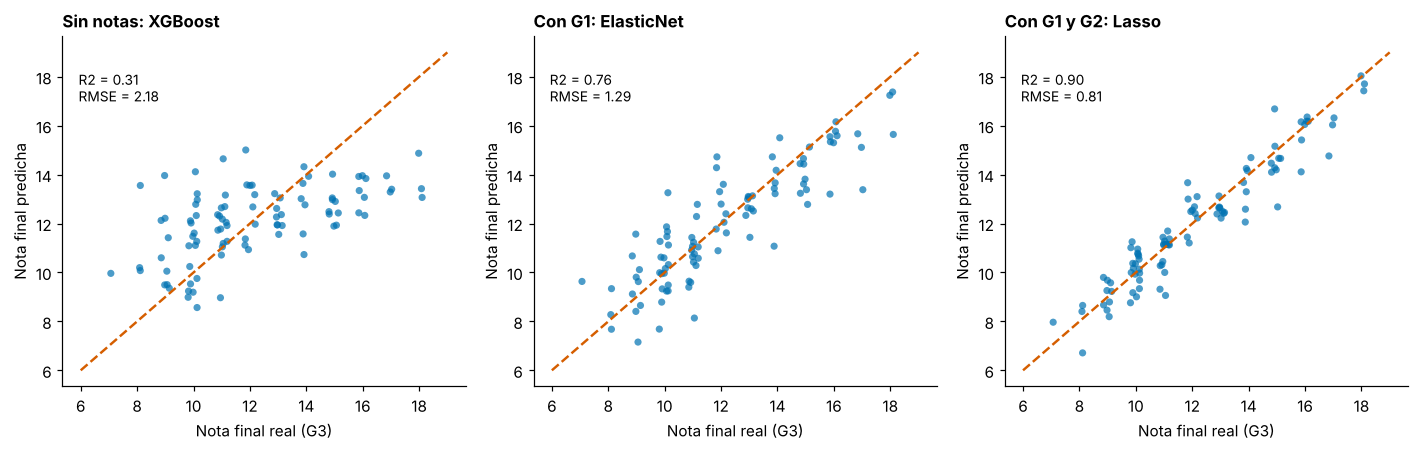

In [13]:
fig, ejes = plt.subplots(1, 3, figsize=(13, 4.2))
for ax, esc in zip(ejes, ESC):
    f = FINAL[("reg", esc)]
    rng = np.random.default_rng(SEMILLA)
    ax.scatter(f["y"] + rng.uniform(-.2, .2, len(f["y"])), f["salida"], s=22, alpha=.7, color=AZUL, edgecolor="none")
    lim = [f["y"].min() - 1, f["y"].max() + 1]; ax.plot(lim, lim, color=NARANJA, ls="--", lw=1.6)
    ax.set_title(f"{esc}: {f['modelo']}"); ax.set_xlabel("Nota final real (G3)"); ax.set_ylabel("Nota final predicha")
    ax.text(0.04, 0.9, f"R2 = {f['met']['R2']:.2f}\nRMSE = {f['met']['RMSE']:.2f}", transform=ax.transAxes, fontsize=9, va="top")
fig.tight_layout(); plt.show()

Figura 4. Nota final predicha frente a la real en el conjunto de prueba para el modelo final de regresión de cada escenario. Fuente: elaboración propia con datos de Cortez y Silva (2008).

Análisis. En el conjunto de prueba, la regresión sin notas mejora de forma clara al modelo base: el RMSE baja de 2,45 a 2,18 (una reducción de 11 %) y el R² sube de 0,12 a 0,31, es decir que con solo información de contexto se explica cerca de un tercio de la variación de la nota final. El error medio absoluto es de 1,8 puntos en la escala de 0 a 20. Con G1, el modelo final (ElasticNet) y el base prácticamente empatan (RMSE de 1,29 frente a 1,31), y con G1 y G2 el modelo final (Lasso) obtiene un RMSE de 0,81 y un R² de 0,90 frente a 0,83 y 0,90 del base, una mejora de 2,6 % que queda dentro del margen de incertidumbre (el intervalo de confianza del RMSE es de 0,69 a 0,94). En términos prácticos, con las dos notas parciales se predice la nota final con un error típico menor a un punto; con G1 el error es de unos 1,3 puntos; y sin ninguna nota el error es de unos 2,2 puntos, que es útil para priorizar pero no para predecir con precisión. Los R² de prueba son parecidos a los de validación (0,31 contra 0,37 sin notas), lo que indica que los modelos generalizan sin una caída fuerte.

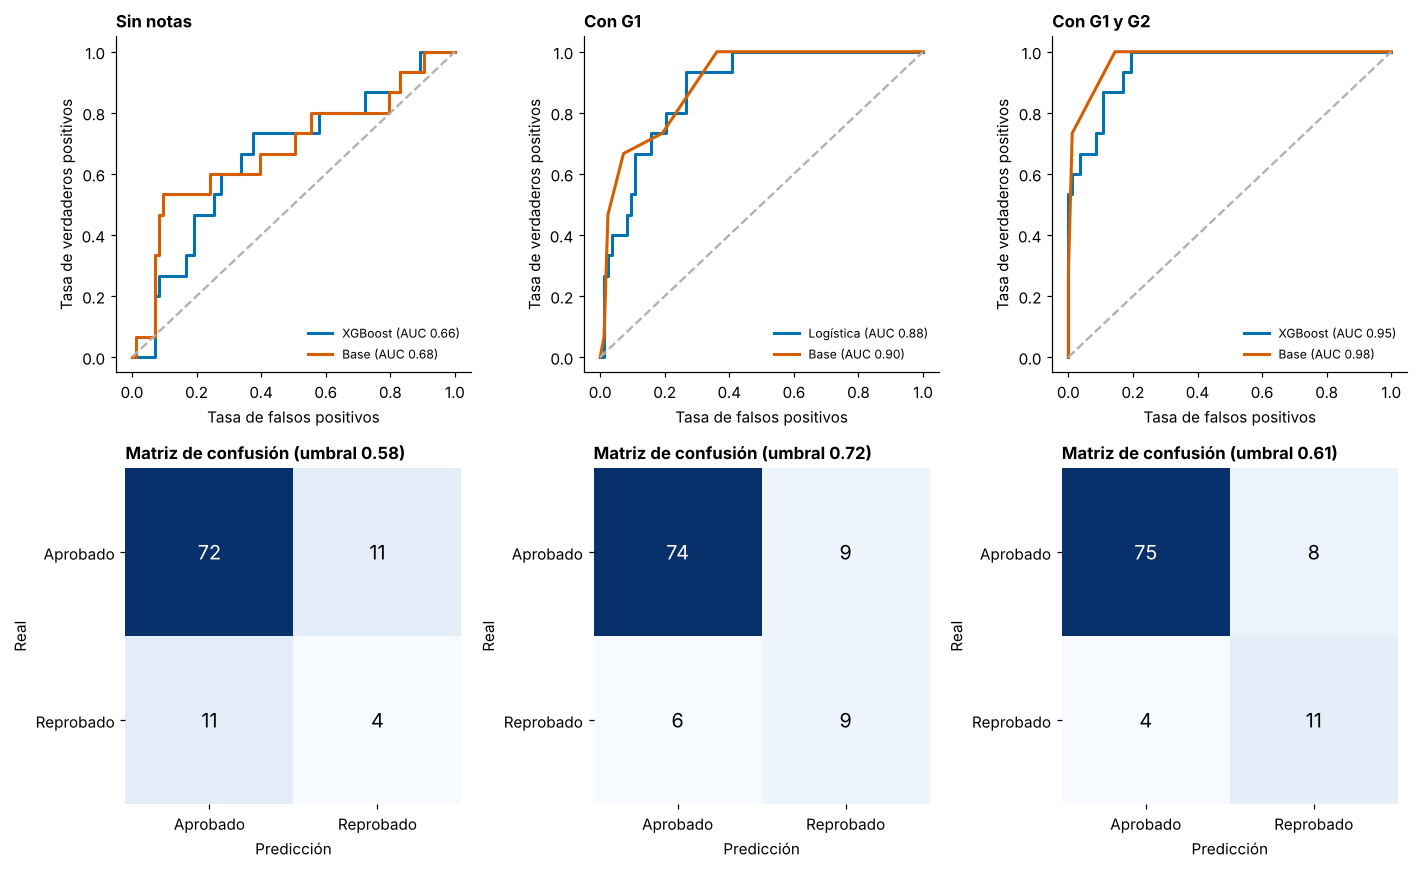

In [14]:
fig, ejes = plt.subplots(2, 3, figsize=(13, 8))
for col, esc in enumerate(ESC):
    f = FINAL[("clf", esc)]
    fpr, tpr, _ = roc_curve(f["y"], f["salida"]); fb, tb, _ = roc_curve(f["y_base"], f["salida_base"])
    ax = ejes[0, col]
    ax.plot(fpr, tpr, color=AZUL, lw=2, label=f"{f['modelo']} (AUC {f['met']['AUC']:.2f})")
    ax.plot(fb, tb, color=NARANJA, lw=2, label=f"Base (AUC {f['met_base']['AUC']:.2f})"); ax.plot([0, 1], [0, 1], color=GRIS, ls="--")
    ax.set_title(esc); ax.set_xlabel("Tasa de falsos positivos"); ax.set_ylabel("Tasa de verdaderos positivos"); ax.legend(fontsize=8, loc="lower right")
    ax = ejes[1, col]
    cm = confusion_matrix(f["y"], (f["salida"] >= f["umbral"]).astype(int))
    ax.imshow(cm, cmap="Blues")
    for i in range(2):
        for j in range(2): ax.text(j, i, cm[i, j], ha="center", va="center", fontsize=13, color="white" if cm[i, j] > cm.max() / 2 else "black")
    ax.set_xticks([0, 1]); ax.set_xticklabels(["Aprobado", "Reprobado"]); ax.set_yticks([0, 1]); ax.set_yticklabels(["Aprobado", "Reprobado"])
    ax.set_xlabel("Predicción"); ax.set_ylabel("Real"); ax.set_title(f"Matriz de confusión (umbral {f['umbral']:.2f})")
    for s in ax.spines.values(): s.set_visible(False)
fig.tight_layout(); plt.show()

Figura 5. Curvas ROC del modelo final y del modelo base, y matrices de confusión del modelo final, en el conjunto de prueba. Fuente: elaboración propia con datos de Cortez y Silva (2008).

Análisis. Aquí los resultados son menos favorables y hay que decirlo con claridad: los modelos ajustados no superan de forma consistente a los modelos base en el conjunto de prueba. Sin notas, XGBoost obtiene un F1 de 0,27 (intervalo de 0,07 a 0,48) y un AUC de 0,66 (intervalo de 0,48 a 0,82), frente a 0,40 y 0,68 del base. Con G1 la regresión logística logra un F1 de 0,55 contra 0,52 del base y un AUC de 0,88 contra 0,90. Con G1 y G2, XGBoost tiene un F1 de 0,65 y un AUC de 0,95, frente a 0,71 y 0,98 del base, que sigue siendo muy difícil de superar. Los intervalos de confianza son muy amplios y se traslapan por completo con los del base, porque la prueba tiene solo 15 reprobados; con tan pocos casos, un estudiante cambia el recall en 6,7 puntos.

Hay varias razones para que no se note una mejora. Primero, con G1 o G2 la tarea es casi un umbral sobre una nota parcial, y un modelo simple ya la captura bien. Segundo, los modelos flexibles sobreajustan (como se vio con AP de 1,00 en entrenamiento) y con 551 estudiantes para entrenar no hay datos suficientes para que compensen. Tercero, el AUC de XGBoost sin notas pasó de 0,81 en validación a 0,66 en prueba, que es lo esperable de elegir el mejor entre cinco candidatos con una validación de 15 reprobados. Cuarto, el ajuste del umbral (0,58 sin notas) se hace con probabilidades fuera de muestra y no garantiza un mejor F1 en otra muestra pequeña. La lectura prudente es que, en la clasificación, la ventaja de los modelos complejos sobre los simples no se pudo demostrar con estos datos, y que el modelo sin notas tiene una capacidad limitada (AUC de 0,66 en prueba). Estos resultados no se ajustaron después de ver la prueba, para no contaminarla.

## 8. Interpretabilidad

### 8.1 Valores SHAP

Se explican los modelos de árboles ajustados con el entrenamiento (el mejor Random Forest o XGBoost de cada escenario según la validación) sobre los estudiantes de validación. Se muestran dos casos: la clasificación sin notas, que es la más útil para intervenir temprano, y la regresión sin notas. Cada punto es un estudiante; el color indica si el valor de la variable es alto (rojo) o bajo (azul) y la posición horizontal indica cuánto empuja la predicción.

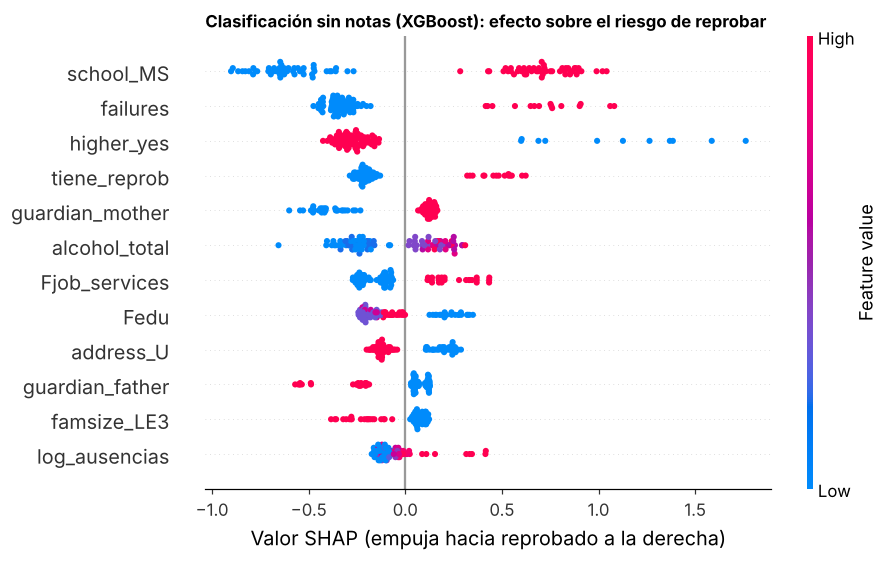

In [15]:
def mejor_arbol(tarea, esc):
    clave = "RMSE" if tarea == "reg" else "AP"
    cand = [m for m in ["Random Forest", "XGBoost"]]
    return (min if tarea == "reg" else max)(cand, key=lambda m: VAL[(tarea, esc, m)][clave])

def valores_shap(tarea, esc):
    nombre = mejor_arbol(tarea, esc)
    est = (R_REG if tarea == "reg" else R_CLF)[(esc, nombre)]["gs"].best_estimator_
    Xv, _ = obtener(tarea, ["validación"], ESC[esc] + nominales)
    pre = est.named_steps["pre"]; Zv = pre.transform(Xv)
    sv = shap.TreeExplainer(est.named_steps["m"]).shap_values(Zv)
    if isinstance(sv, list): sv = sv[1]
    elif getattr(sv, "ndim", 2) == 3: sv = sv[:, :, 1]
    nombres = [n.split("__", 1)[1] for n in pre.get_feature_names_out()]
    return nombre, sv, Zv, nombres

SHAPV = {}
for tarea, esc in [("clf", "Sin notas"), ("reg", "Sin notas"), ("reg", "Con G1 y G2")]:
    SHAPV[(tarea, esc)] = valores_shap(tarea, esc)

nombre, sv, Zv, nombres = SHAPV[("clf", "Sin notas")]
shap.summary_plot(sv, Zv, feature_names=nombres, max_display=12, show=False)
plt.gcf().set_size_inches(8.5, 5.2); plt.title(f"Clasificación sin notas ({nombre}): efecto sobre el riesgo de reprobar", loc="left", fontsize=11, fontweight="bold")
plt.xlabel("Valor SHAP (empuja hacia reprobado a la derecha)"); plt.tight_layout(); plt.show()

Figura 6. Valores SHAP de la clasificación sin notas: las doce variables con mayor efecto sobre la probabilidad de reprobar. Fuente: elaboración propia con datos de Cortez y Silva (2008).

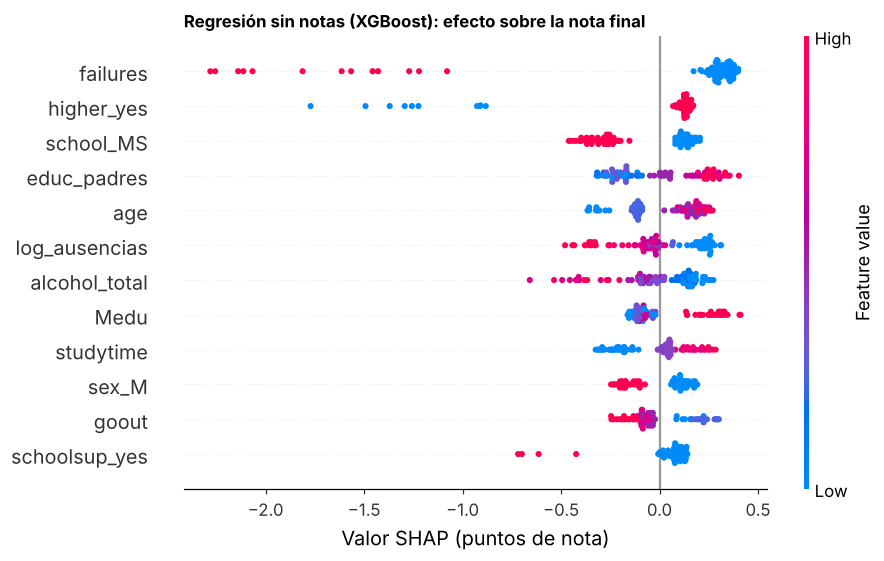

In [16]:
nombre, sv, Zv, nombres = SHAPV[("reg", "Sin notas")]
shap.summary_plot(sv, Zv, feature_names=nombres, max_display=12, show=False)
plt.gcf().set_size_inches(8.5, 5.2); plt.title(f"Regresión sin notas ({nombre}): efecto sobre la nota final", loc="left", fontsize=11, fontweight="bold")
plt.xlabel("Valor SHAP (puntos de nota)"); plt.tight_layout(); plt.show()

Figura 7. Valores SHAP de la regresión sin notas: las doce variables con mayor efecto sobre la nota final predicha. Fuente: elaboración propia con datos de Cortez y Silva (2008).

Análisis. Los dos gráficos muestran un patrón coherente. En la clasificación sin notas, las variables con mayor efecto son la escuela MS (empuja hacia reprobar), las reprobaciones previas, no querer cursar educación superior (las estudiantes sin ese deseo reciben los empujes más fuertes hacia reprobar, de hasta 1,7 en la escala del modelo) y el indicador de reprobaciones previas. También aportan, con menos fuerza, un consumo total de alcohol alto y la educación del padre: a mayor nivel educativo del padre, menor riesgo. En la regresión sin notas aparecen las mismas variables: tener una reprobación previa resta entre 1 y 2,3 puntos a la nota predicha, no querer estudiar educación superior resta entre 0,9 y 1,8 puntos, y estudiar en MS resta cerca de medio punto. Un mayor nivel educativo de los padres, más tiempo de estudio y menos ausencias y menos alcohol se asocian con notas más altas. Hay que recordar que son asociaciones del modelo y no causas: por ejemplo, el nombre de la escuela puede estar recogiendo diferencias de contexto que no están en el archivo, y recibir apoyo adicional de la escuela (schoolsup) resta puntos probablemente porque lo reciben quienes ya van mal.

### 8.2 Importancia por permutación

Para comparar escenarios con una misma herramienta se calcula la importancia por permutación sobre el mejor modelo de scikit-learn de cada caso, usando la validación. Se desordena cada variable original (no las columnas codificadas) y se mide cuánto empeora el error o la precisión promedio, repitiendo 15 veces.

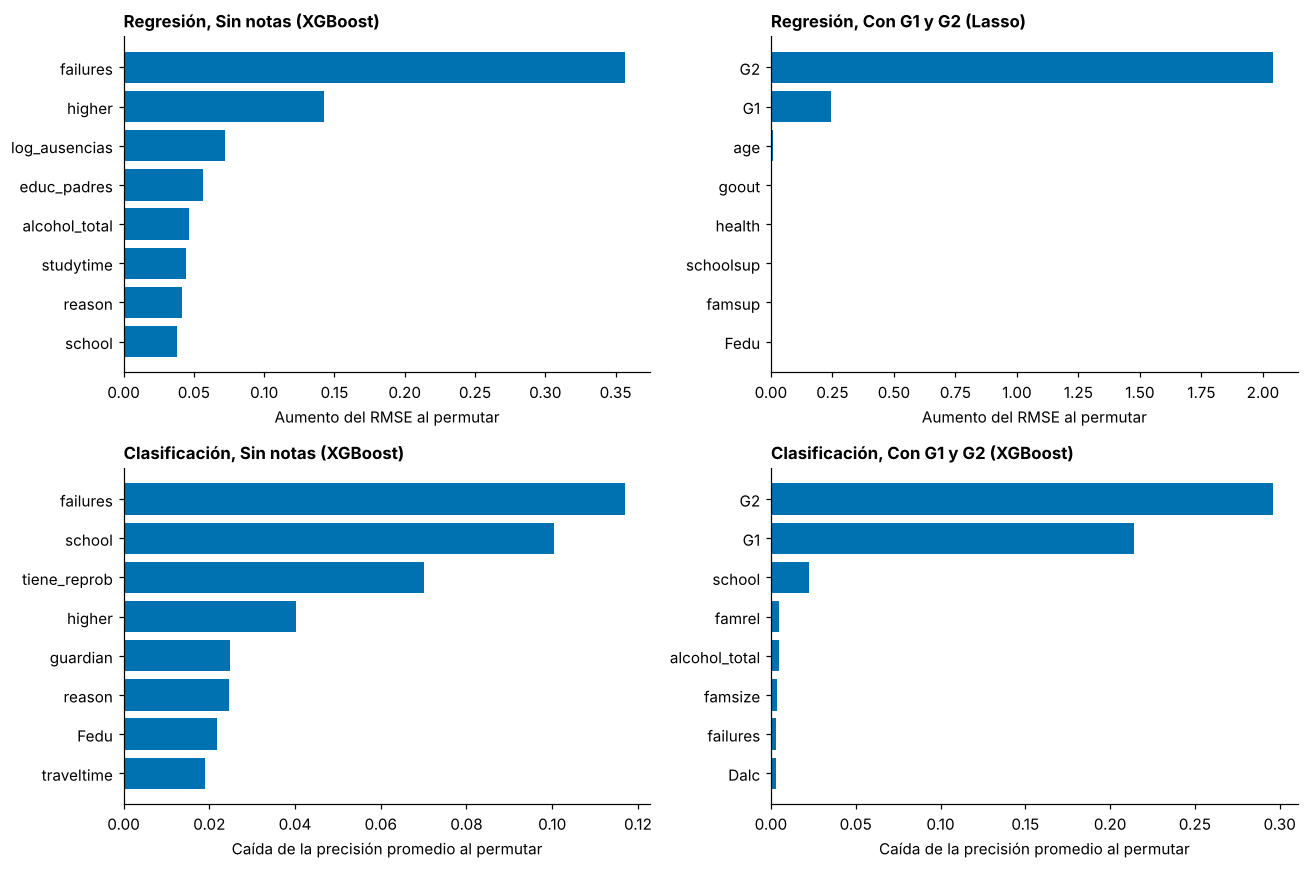

In [17]:
def perm(tarea, esc):
    clave = "RMSE" if tarea == "reg" else "AP"
    cands = [m for m in MODELOS[tarea] if m != "MLP (PyTorch)"]
    nombre = (min if tarea == "reg" else max)(cands, key=lambda m: VAL[(tarea, esc, m)][clave])
    est = (R_REG if tarea == "reg" else R_CLF)[(esc, nombre)]["gs"].best_estimator_
    Xv, yv = obtener(tarea, ["validación"], ESC[esc] + nominales)
    r = permutation_importance(est, Xv, yv, scoring="neg_root_mean_squared_error" if tarea == "reg" else "average_precision",
                               n_repeats=3 if RAPIDO else 15, random_state=SEMILLA, n_jobs=1)
    s = pd.Series(r.importances_mean, index=Xv.columns).sort_values(ascending=False)
    return nombre, s

fig, ejes = plt.subplots(2, 2, figsize=(12, 8))
PERM = {}
for ax, (tarea, esc) in zip(ejes.flat, [("reg", "Sin notas"), ("reg", "Con G1 y G2"), ("clf", "Sin notas"), ("clf", "Con G1 y G2")]):
    nombre, s = perm(tarea, esc); PERM[(tarea, esc)] = s
    top = s.head(8)[::-1]
    ax.barh(top.index, top.values, color=AZUL)
    ax.set_title(f"{'Regresión' if tarea == 'reg' else 'Clasificación'}, {esc} ({nombre})")
    ax.set_xlabel("Aumento del RMSE al permutar" if tarea == "reg" else "Caída de la precisión promedio al permutar")
fig.tight_layout(); plt.show()

Figura 8. Importancia por permutación de las ocho variables más relevantes en regresión y clasificación, sin notas y con G1 y G2. Fuente: elaboración propia con datos de Cortez y Silva (2008).

Análisis. La importancia por permutación confirma lo anterior y deja clara la diferencia entre escenarios. Sin notas, en regresión la variable más importante es de lejos el número de reprobaciones previas (el RMSE aumenta 0,36 al desordenarla), seguida del deseo de cursar educación superior (0,14), las ausencias en logaritmo, la educación de los padres y el alcohol total; en clasificación el orden es reprobaciones previas, escuela, indicador de reprobaciones previas y deseo de estudios superiores. Con G1 y G2 el panorama cambia por completo: en regresión permutar G2 aumenta el RMSE en más de 2 puntos y G1 en 0,25, mientras que todas las demás variables tienen una importancia prácticamente nula, y en clasificación G2 y G1 dominan con una caída de la AP de 0,30 y 0,21, con la escuela como única variable del contexto que aporta algo (0,02). Esto explica por qué Lasso ignora casi todo el contexto cuando conoce las notas parciales, y por qué los modelos con G1 y G2 no mejoran mucho a los simples: una vez que se conoce el desempeño reciente, las variables de contexto y hábitos prácticamente no agregan información. Su valor está en el escenario sin notas, que es el único en que se puede anticipar el riesgo antes de que aparezcan las primeras calificaciones.

## 9. Aprendizaje no supervisado: segmentación de estudiantes

### 9.1 Variables y preparación

Se agrupa a los estudiantes por hábitos y contexto, sin usar las notas ni la variable objetivo, de modo que los perfiles sean independientes del rendimiento y luego se pueda ver si se relacionan con él. Se usan las mismas 13 variables de la proyección por componentes principales de la Fase 1, con las ausencias en logaritmo como se decidió en la Fase 2: edad, reprobaciones previas, ausencias, nivel educativo de la madre y del padre, tiempo de viaje, tiempo de estudio, relaciones familiares, tiempo libre, salidas, alcohol entre semana y de fin de semana, y salud. Como se había anticipado, la estandarización se ajusta solo con el conjunto de entrenamiento y los grupos se aprenden con esos 454 estudiantes; luego se asignan los de validación y prueba para comprobar que los grupos se sostienen con datos nuevos.

In [18]:
vars_cl = ["age", "failures", "log_ausencias", "Medu", "Fedu", "traveltime", "studytime", "famrel", "freetime", "goout", "Dalc", "Walc", "health"]
etiq_cl = {"age": "Edad", "failures": "Reprobaciones", "log_ausencias": "Ausencias (log)", "Medu": "Educ. madre", "Fedu": "Educ. padre", "traveltime": "Tiempo de viaje",
           "studytime": "Tiempo de estudio", "famrel": "Rel. familiares", "freetime": "Tiempo libre", "goout": "Salidas", "Dalc": "Alcohol semana", "Walc": "Alcohol fin de sem.", "health": "Salud"}
tr = df.loc[idx["entrenamiento"]]; va = df.loc[idx["validación"]]
esc_cl = StandardScaler().fit(tr[vars_cl])
Z_tr, Z_va, Z_all = esc_cl.transform(tr[vars_cl]), esc_cl.transform(va[vars_cl]), esc_cl.transform(df[vars_cl])
pca_cl = PCA(n_components=0.80, random_state=SEMILLA).fit(Z_tr)
P_tr, P_va = pca_cl.transform(Z_tr), pca_cl.transform(Z_va)
print("Componentes principales que retienen el 80 % de la varianza:", pca_cl.n_components_)

filas = []
for k in range(2, 11):
    km = KMeans(n_clusters=k, n_init=20, random_state=SEMILLA).fit(Z_tr)
    kp = KMeans(n_clusters=k, n_init=20, random_state=SEMILLA).fit(P_tr)
    filas.append({"K": k, "Inercia": km.inertia_, "Silueta (entren.)": silhouette_score(Z_tr, km.labels_), "Silueta (valid.)": silhouette_score(Z_va, km.predict(Z_va)),
                  "Davies-Bouldin": davies_bouldin_score(Z_tr, km.labels_), "Silueta en espacio PCA": silhouette_score(P_tr, kp.labels_)})
tabla_k = pd.DataFrame(filas).set_index("K")
# Regla definida de antemano: K con mayor silueta de entrenamiento entre 3 y 8 (con 2 grupos la segmentación sería demasiado gruesa para perfilar)
K_ELEGIDO = int(tabla_k.loc[3:8, "Silueta (entren.)"].idxmax())
print("K elegido:", K_ELEGIDO)
tabla_k.round(3)

Componentes principales que retienen el 80 % de la varianza: 9


K elegido: 4


,Inercia,Silueta (entren.),Silueta (valid.),Davies-Bouldin,Silueta en espacio PCA
K,,,,,
2,5225.624,0.136,0.125,2.615,0.154
3,4772.700,0.099,0.103,2.455,0.119
4,4468.280,0.101,0.100,2.260,0.121
5,4253.470,0.090,0.089,2.284,0.105
6,4087.665,0.088,0.065,2.254,0.109
7,3951.267,0.081,0.059,2.256,0.111
8,3802.936,0.088,0.057,2.126,0.108
9,3689.181,0.089,0.059,2.047,0.107
10,3589.846,0.094,0.065,2.004,0.108


Tabla 10. K-Means en el conjunto de entrenamiento: inercia, silueta (en el espacio original y en validación), índice de Davies-Bouldin y silueta en el espacio reducido por componentes principales, para K de 2 a 10. La regla para elegir K, definida antes de ver los resultados, fue tomar el K con mayor silueta entre 3 y 8, porque con solo dos grupos los perfiles serían demasiado generales. Fuente: elaboración propia con datos de Cortez y Silva (2008).

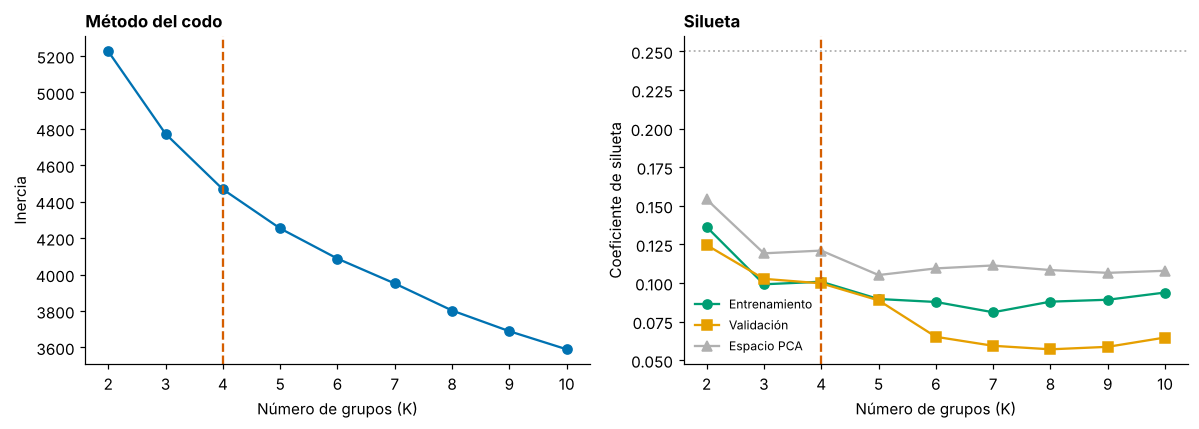

In [19]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(11, 4))
ax1.plot(tabla_k.index, tabla_k["Inercia"], marker="o", color=AZUL); ax1.axvline(K_ELEGIDO, color=NARANJA, ls="--")
ax1.set_xlabel("Número de grupos (K)"); ax1.set_ylabel("Inercia"); ax1.set_title("Método del codo")
ax2.plot(tabla_k.index, tabla_k["Silueta (entren.)"], marker="o", color=VERDE, label="Entrenamiento")
ax2.plot(tabla_k.index, tabla_k["Silueta (valid.)"], marker="s", color=AMARILLO, label="Validación")
ax2.plot(tabla_k.index, tabla_k["Silueta en espacio PCA"], marker="^", color=GRIS, label="Espacio PCA")
ax2.axvline(K_ELEGIDO, color=NARANJA, ls="--"); ax2.axhline(0.25, color=GRIS, ls=":", lw=1.2)
ax2.set_xlabel("Número de grupos (K)"); ax2.set_ylabel("Coeficiente de silueta"); ax2.set_title("Silueta"); ax2.legend(fontsize=8)
fig.tight_layout(); plt.show()

Figura 9. Método del codo y coeficiente de silueta de K-Means; la línea naranja marca el K elegido y la línea punteada gris el 0,25 fijado como meta en la Fase 1. Fuente: elaboración propia con datos de Cortez y Silva (2008).

Análisis. El coeficiente de silueta es bajo para todos los valores de K: el máximo es de 0,136 con K igual a 2 y, entre 3 y 8 grupos, no pasa de 0,101. Ni siquiera se acerca a la meta de 0,25 planteada en la Fase 1. Tampoco hay un codo claro: la inercia baja de forma gradual (de 4.773 con K de 3 a 4.468 con K de 4 y a 4.253 con K de 5) sin un quiebre que sugiera un número natural de grupos. Aplicando la regla definida de antemano (mayor silueta entre 3 y 8), el K elegido es 4, con una silueta de 0,101 en entrenamiento y de 0,100 en validación; que ambos valores coincidan indica que los grupos se mantienen con estudiantes nuevos. Reducir la dimensionalidad con componentes principales no ayuda (silueta de 0,12 para K igual a 4). El resultado es coherente con lo que se vio en la Fase 1, donde los estudiantes aparecían en una sola nube continua en el plano de componentes: los hábitos y el contexto no forman grupos naturales separados, así que los grupos que se encuentran son una partición útil de un continuo y no categorías nítidas. Esto se debe tener presente al interpretarlos.

### 9.2 DBSCAN y clustering jerárquico

DBSCAN necesita dos parámetros: el radio eps y el mínimo de vecinos. Para orientar eps se mira la distancia de cada estudiante a su k-ésimo vecino más cercano, ordenada de menor a mayor; el codo de esa curva sugiere un valor razonable. Luego se recorre una pequeña cuadrícula y se acepta una solución solo si tiene al menos dos grupos y no más de 25 % de ruido. El clustering jerárquico se hace con enlace de Ward y el mismo K que K-Means, y se muestra su dendrograma.

Ninguna configuración de DBSCAN cumple la condición (al menos 2 grupos y como máximo 25 % de ruido).


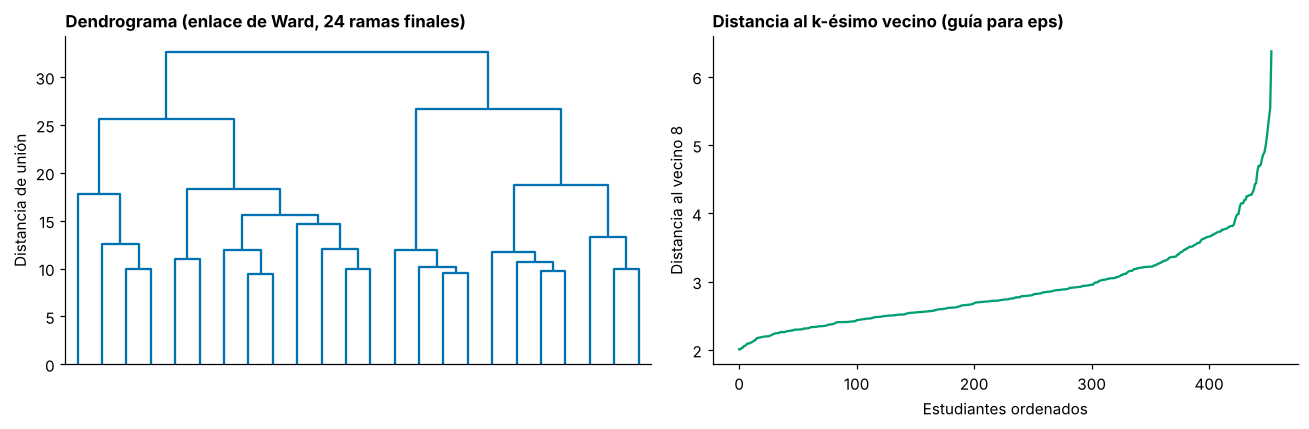

Grupos  % ruido  Silueta (sin ruido)
eps min_samples                                      
2.5 5                 1     33.0                  NaN
    8                 1     37.9                  NaN
    12                1     50.0                  NaN
3.0 5                 1     12.6                  NaN
    8                 1     14.1                  NaN
    12                1     15.4                  NaN
3.5 5                 1      5.3                  NaN
    8                 1      5.7                  NaN
    12                1      6.2                  NaN
4.0 5                 1      2.6                  NaN
    8                 1      3.3                  NaN
    12                1      3.3                  NaN
4.5 5                 1      0.7                  NaN
    8                 1      0.9                  NaN
    12                1      1.1                  NaN
5.0 5                 1      0.2                  NaN
    8                 1      0.2                  NaN
    12                1      0.2                  NaN

In [20]:
ms_ref = 8
dist = np.sort(NearestNeighbors(n_neighbors=ms_ref).fit(Z_tr).kneighbors(Z_tr)[0][:, -1])
filas = []
for eps in [2.5, 3.0, 3.5, 4.0, 4.5, 5.0]:
    for ms in [5, 8, 12]:
        lab = DBSCAN(eps=eps, min_samples=ms).fit_predict(Z_tr)
        nc = len(set(lab)) - (1 if -1 in lab else 0); ruido = (lab == -1).mean() * 100
        sil = silhouette_score(Z_tr[lab != -1], lab[lab != -1]) if nc >= 2 and (lab != -1).sum() > nc else np.nan
        filas.append({"eps": eps, "min_samples": ms, "Grupos": nc, "% ruido": round(ruido, 1), "Silueta (sin ruido)": sil})
tabla_db = pd.DataFrame(filas).set_index(["eps", "min_samples"])
validas = tabla_db[(tabla_db["Grupos"] >= 2) & (tabla_db["% ruido"] <= 25)]
if len(validas):
    eps_db, ms_db = validas["Silueta (sin ruido)"].idxmax()
    lab_db = DBSCAN(eps=eps_db, min_samples=ms_db).fit_predict(Z_tr)
    print(f"DBSCAN elegido: eps={eps_db}, min_samples={ms_db}")
else:
    eps_db = ms_db = lab_db = None
    print("Ninguna configuración de DBSCAN cumple la condición (al menos 2 grupos y como máximo 25 % de ruido).")

agg = AgglomerativeClustering(n_clusters=K_ELEGIDO, linkage="ward").fit(Z_tr)
km_final = KMeans(n_clusters=K_ELEGIDO, n_init=50, random_state=SEMILLA).fit(Z_tr)
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4))
dendrogram(linkage(Z_tr, "ward"), truncate_mode="lastp", p=24, ax=ax1, color_threshold=0, above_threshold_color=AZUL, no_labels=True)
ax1.set_title("Dendrograma (enlace de Ward, 24 ramas finales)"); ax1.set_ylabel("Distancia de unión")
ax2.plot(dist, color=VERDE); ax2.set_xlabel("Estudiantes ordenados"); ax2.set_ylabel(f"Distancia al vecino {ms_ref}"); ax2.set_title("Distancia al k-ésimo vecino (guía para eps)")
fig.tight_layout(); plt.show()
tabla_db.round(3)

Figura 10. Dendrograma del clustering jerárquico y curva de distancias al k-ésimo vecino para orientar el parámetro eps de DBSCAN. Tabla 11 (a continuación): cuadrícula de DBSCAN con número de grupos, porcentaje de ruido y silueta calculada sin los puntos de ruido. Fuente: elaboración propia con datos de Cortez y Silva (2008).

Análisis. DBSCAN no encontró estructura de densidad: en las 18 configuraciones probadas solo hay un grupo. Con un radio pequeño (eps de 2,5) entre 33 % y 50 % de los estudiantes queda como ruido, y con un radio grande (eps de 5) casi todos se funden en un único grupo con 0,2 % de ruido. Nunca aparece un valor intermedio en el que haya dos grupos separados por una zona de baja densidad. Esto confirma, con otro algoritmo, lo que mostraba la silueta: los estudiantes forman una nube continua sin huecos, por lo que ninguna configuración cumple la condición de al menos dos grupos y como máximo 25 % de ruido.

In [21]:
lab_km = km_final.labels_; lab_ag = agg.labels_
filas = [{"Algoritmo": f"K-Means (K = {K_ELEGIDO})", "Grupos": K_ELEGIDO, "Silueta": silhouette_score(Z_tr, lab_km), "Davies-Bouldin": davies_bouldin_score(Z_tr, lab_km), "Concordancia con K-Means (ARI)": 1.0},
         {"Algoritmo": f"Jerárquico, Ward (K = {K_ELEGIDO})", "Grupos": K_ELEGIDO, "Silueta": silhouette_score(Z_tr, lab_ag), "Davies-Bouldin": davies_bouldin_score(Z_tr, lab_ag), "Concordancia con K-Means (ARI)": adjusted_rand_score(lab_km, lab_ag)}]
if lab_db is not None:
    m = lab_db != -1
    filas.append({"Algoritmo": f"DBSCAN (eps = {eps_db}, min_samples = {ms_db})", "Grupos": len(set(lab_db)) - 1, "Silueta": silhouette_score(Z_tr[m], lab_db[m]),
                  "Davies-Bouldin": davies_bouldin_score(Z_tr[m], lab_db[m]), "Concordancia con K-Means (ARI)": adjusted_rand_score(lab_km[m], lab_db[m])})
tabla_algs = pd.DataFrame(filas).set_index("Algoritmo")
tabla_algs.round(3)

,Grupos,Silueta,Davies-Bouldin,Concordancia con K-Means (ARI)
Algoritmo,,,,
K-Means (K = 4),4,0.101,2.260,1.000
"Jerárquico, Ward (K = 4)",4,0.075,2.487,0.483


Tabla 12. Comparación de los tres algoritmos de agrupamiento en el conjunto de entrenamiento. En DBSCAN las métricas excluyen los puntos de ruido. Fuente: elaboración propia con datos de Cortez y Silva (2008).

Análisis. K-Means obtiene una silueta de 0,101 y un índice de Davies-Bouldin de 2,26, y el clustering jerárquico con enlace de Ward, con el mismo número de grupos, una silueta de 0,075 y un índice de 2,49, es decir que K-Means separa algo mejor (menor Davies-Bouldin es mejor). La concordancia entre ambos, medida con el índice de Rand ajustado, es de 0,48, un acuerdo moderado: comparten parte de la estructura, pero asignan distinto a muchos estudiantes, lo que es normal cuando los grupos no están bien separados. DBSCAN no se incluye en la comparación porque no produjo una solución válida. Se elige K-Means para los perfiles por su mejor silueta y porque permite asignar estudiantes nuevos a un grupo, algo que el dashboard de la Fase 4 necesitará.

### 9.3 Perfiles de los grupos de K-Means

Se asignan los 649 estudiantes a los grupos de K-Means (los de validación y prueba por cercanía a los centroides aprendidos con el entrenamiento) y se ordenan los grupos de menor a mayor tasa de reprobación para leerlos más fácil. Las notas no intervinieron en la formación de los grupos; se usan solo para ver si los perfiles tienen valor práctico.

In [22]:
lab_all = km_final.predict(Z_all)
tasa = pd.Series(1 - df["aprobado"].values).groupby(lab_all).mean().sort_values()
mapa = {viejo: nuevo + 1 for nuevo, viejo in enumerate(tasa.index)}
grupo = pd.Series(lab_all, index=df.index).map(mapa); df["grupo"] = grupo
z = pd.DataFrame(Z_all, index=df.index, columns=vars_cl).groupby(grupo).mean()

perfil = pd.DataFrame({
    "Estudiantes": grupo.value_counts().sort_index(),
    "% del total": (grupo.value_counts(normalize=True).sort_index() * 100).round(1),
    "% reprobados": df.groupby(grupo).apply(lambda d: (1 - d["aprobado"]).mean() * 100),
    "% con G3 = 0": df.groupby(grupo)["sin_nota_final"].mean() * 100,
    "G3 medio (sin ceros)": df[df["G3"] > 0].groupby(grupo)["G3"].mean(),
    "% escuela MS": df["school"].eq("MS").groupby(grupo).mean() * 100,
    "% quiere educ. superior": df["higher"].eq("yes").groupby(grupo).mean() * 100,
})
medias = df.groupby(grupo)[["age", "failures", "absences", "studytime", "goout", "Dalc", "Walc", "Medu", "Fedu"]].mean()
perfil = perfil.join(medias.round(2))
chi_p = stats.chi2_contingency(pd.crosstab(grupo, df["aprobado"]), correction=False)[1]
kw_p = stats.kruskal(*[g["G3"].values for _, g in df[df["G3"] > 0].groupby("grupo")])[1]
print(f"Chi cuadrado grupo contra aprobación: p = {chi_p:.2e} | Kruskal-Wallis de G3 entre grupos: p = {kw_p:.2e}")
print("Silueta en validación con los grupos asignados:", round(silhouette_score(Z_va, km_final.predict(Z_va)), 3))
perfil.round(2)

Chi cuadrado grupo contra aprobación: p = 1.68e-19 | Kruskal-Wallis de G3 entre grupos: p = 2.15e-30
Silueta en validación con los grupos asignados: 0.1


,Estudiantes,% del total,% reprobados,% con G3 = 0,G3 medio (sin ceros),% escuela MS,% quiere educ. superior,age,failures,absences,studytime,goout,Dalc,Walc,Medu,Fedu
1,212,32.7,5.19,1.42,13.54,19.34,98.58,16.50,0.01,2.63,2.13,2.95,1.16,1.76,3.55,3.24
2,243,37.4,12.35,1.65,12.19,44.03,89.30,16.60,0.08,2.77,2.00,2.79,1.18,1.76,1.76,1.55
3,133,20.5,19.55,1.50,11.27,33.83,87.22,16.79,0.13,6.00,1.66,4.20,2.57,3.98,2.59,2.46
4,61,9.4,54.10,9.84,9.22,54.10,62.30,18.08,1.72,5.69,1.54,3.34,1.67,2.44,1.77,1.74


Tabla 13. Perfil de los grupos de K-Means con los 649 estudiantes: tamaño, tasa de reprobación, nota final media y promedios de variables seleccionadas. Fuente: elaboración propia con datos de Cortez y Silva (2008).

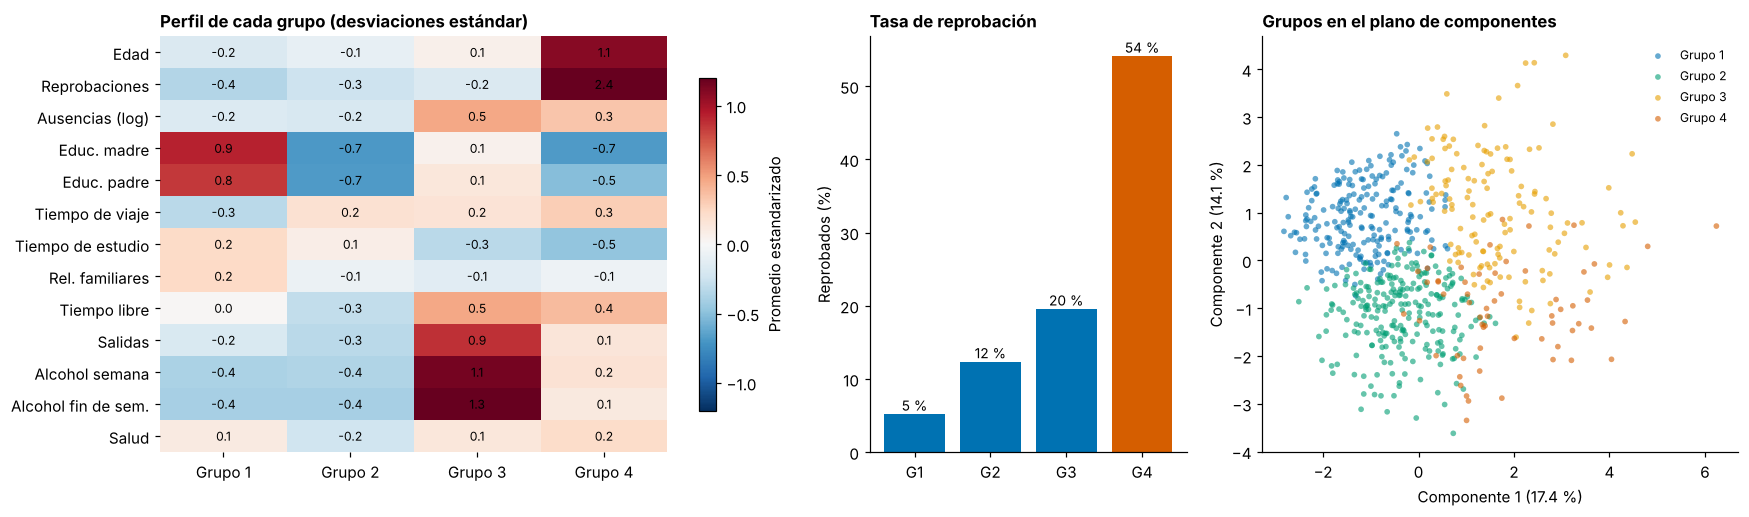

In [23]:
fig, (ax1, ax2, ax3) = plt.subplots(1, 3, figsize=(16, 4.8), gridspec_kw={"width_ratios": [1.6, 0.8, 1.2]})
im = ax1.imshow(z.values.T, cmap="RdBu_r", vmin=-1.2, vmax=1.2, aspect="auto")
ax1.set_xticks(range(K_ELEGIDO)); ax1.set_xticklabels([f"Grupo {g}" for g in z.index]); ax1.set_yticks(range(len(vars_cl))); ax1.set_yticklabels([etiq_cl[v] for v in vars_cl])
for i in range(len(vars_cl)):
    for j in range(K_ELEGIDO): ax1.text(j, i, f"{z.values[j, i]:.1f}", ha="center", va="center", fontsize=8)
for s in ax1.spines.values(): s.set_visible(False)
fig.colorbar(im, ax=ax1, shrink=0.8).set_label("Promedio estandarizado"); ax1.set_title("Perfil de cada grupo (desviaciones estándar)")
ax2.bar([f"G{g}" for g in perfil.index], perfil["% reprobados"], color=[NARANJA if v == perfil["% reprobados"].max() else AZUL for v in perfil["% reprobados"]])
for i, v in enumerate(perfil["% reprobados"]): ax2.text(i, v + 0.5, f"{v:.0f} %", ha="center", fontsize=9)
ax2.set_ylabel("Reprobados (%)"); ax2.set_title("Tasa de reprobación")
pcs = PCA(n_components=2, random_state=SEMILLA).fit(Z_tr); Pall = pcs.transform(Z_all)
paleta = [AZUL, VERDE, AMARILLO, NARANJA, CELESTE, GRIS, "#CC79A7", "#000000"]
for g in sorted(grupo.unique()):
    mk = (grupo == g).values; ax3.scatter(Pall[mk, 0], Pall[mk, 1], s=14, alpha=.6, color=paleta[g - 1], label=f"Grupo {g}", edgecolor="none")
ax3.set_xlabel(f"Componente 1 ({pcs.explained_variance_ratio_[0] * 100:.1f} %)"); ax3.set_ylabel(f"Componente 2 ({pcs.explained_variance_ratio_[1] * 100:.1f} %)")
ax3.set_title("Grupos en el plano de componentes"); ax3.legend(fontsize=8)
fig.tight_layout(); plt.show()

Figura 11. Perfil estandarizado de cada grupo de K-Means, tasa de reprobación por grupo y proyección de los grupos sobre las dos primeras componentes principales. Fuente: elaboración propia con datos de Cortez y Silva (2008).

Análisis. A pesar de la silueta baja, los grupos sí distinguen riesgos de manera muy marcada: la tasa de reprobación va de 5 % a 54 % (chi cuadrado con la aprobación, p de 1,7 × 10⁻¹⁹; Kruskal-Wallis de G3 entre grupos, p de 2,2 × 10⁻³⁰), aunque las notas no se usaron para formarlos. Los cuatro perfiles son los siguientes.

El grupo 1 (212 estudiantes, 32,7 %) son hogares con mayor nivel educativo (madre 3,6 y padre 3,2 en la escala de 0 a 4), consumo de alcohol bajo, el mayor tiempo de estudio y casi todos quieren estudios superiores (98,6 %); reprueban solo el 5,2 % y su nota media es de 13,5. El grupo 2 (243 estudiantes, 37,4 %) comparte hábitos moderados pero con hogares de menor nivel educativo (madre 1,8 y padre 1,6) y más presencia de la escuela MS (44 %); reprueban el 12,4 %. El grupo 3 (133 estudiantes, 20,5 %) se caracteriza por una vida social intensa: salidas con amigos (4,2) y el consumo de alcohol más alto, sobre todo en fin de semana (4,0), menos tiempo de estudio y más ausencias (6,0); reprueban el 19,6 %. El grupo 4 (61 estudiantes, 9,4 %) es el de rezago: son mayores (18,1 años), con 1,7 reprobaciones previas en promedio, solo 62 % quiere estudios superiores y el 54 % es de MS; reprueba el 54,1 % y tiene la mayor proporción de ceros en la nota final (9,8 %, unos 6 de los 15 casos).

Valor práctico: el grupo 4, con el 9 % de los estudiantes, reúne cerca de un tercio de los reprobados (33 de 100), y los grupos 3 y 4 juntos, con el 30 % de los estudiantes, reúnen cerca del 59 %. Una escuela podría usar estos perfiles para decidir qué tipo de apoyo ofrecer: orientación académica y repaso al grupo 4, acompañamiento en hábitos y bienestar al grupo 3, y apoyo familiar al grupo 2. Una advertencia: la edad y las reprobaciones previas son variables de entrada de la segmentación, y están muy relacionadas con el resultado, por lo que parte de la diferencia del grupo 4 es esperable por construcción.

## 10. Verificación de objetivos y conclusiones

En la Fase 1 se plantearon metas medibles para esta fase: que el mejor modelo de regresión supere al base en RMSE, que el mejor de clasificación lo supere en F1 de la clase reprobado, que haya al menos dos modelos de cada tipo más un perceptrón multicapa, y que la segmentación alcance una silueta promedio de al menos 0,25. La siguiente tabla las contrasta con los resultados en el conjunto de prueba.

In [24]:
filas = []
for esc in ESC:
    f = FINAL[("reg", esc)]
    filas.append({"Meta": f"Regresión ({esc}): RMSE menor que el base", "Resultado": f"{f['met']['RMSE']:.2f} frente a {f['met_base']['RMSE']:.2f}", "Cumplida": "Sí" if f["met"]["RMSE"] < f["met_base"]["RMSE"] else "No"})
for esc in ESC:
    f = FINAL[("clf", esc)]
    filas.append({"Meta": f"Clasificación ({esc}): F1 mayor que el base", "Resultado": f"{f['met']['F1']:.2f} frente a {f['met_base']['F1']:.2f}", "Cumplida": "Sí" if f["met"]["F1"] > f["met_base"]["F1"] else "No"})
filas.append({"Meta": "Al menos dos modelos de regresión y dos de clasificación, más MLP en PyTorch", "Resultado": "5 de regresión, 4 de clasificación y MLP en ambas tareas", "Cumplida": "Sí"})
sil_ent = silhouette_score(Z_tr, km_final.labels_)
filas.append({"Meta": "Silueta promedio de al menos 0,25 en la segmentación", "Resultado": f"{sil_ent:.2f} (K-Means, K = {K_ELEGIDO})", "Cumplida": "Sí" if sil_ent >= 0.25 else "No"})
tabla_meta = pd.DataFrame(filas).set_index("Meta")
tabla_meta

,Resultado,Cumplida
Meta,,
Regresión (Sin notas): RMSE menor que el base,2.18 frente a 2.45,Sí
Regresión (Con G1): RMSE menor que el base,1.29 frente a 1.30,Sí
Regresión (Con G1 y G2): RMSE menor que el base,0.81 frente a 0.83,Sí
Clasificación (Sin notas): F1 mayor que el base,0.27 frente a 0.40,No
Clasificación (Con G1): F1 mayor que el base,0.55 frente a 0.52,Sí
Clasificación (Con G1 y G2): F1 mayor que el base,0.65 frente a 0.71,No
"Al menos dos modelos de regresión y dos de clasificación, más MLP en PyTorch","5 de regresión, 4 de clasificación y MLP en am...",Sí
"Silueta promedio de al menos 0,25 en la segmentación","0.10 (K-Means, K = 4)",No


Tabla 14. Cumplimiento de las metas de la Fase 3 planteadas en los objetivos SMART. Fuente: elaboración propia.

Esta fase se desarrolló con el protocolo definido antes de ver los resultados y sin modificarlo después de abrir el conjunto de prueba. El balance es mixto y conviene presentarlo tal cual.

En regresión los resultados son buenos. Con G1 y G2, el modelo final (Lasso) predice la nota final con un RMSE de 0,81 y un R² de 0,90 en prueba, es decir un error típico menor a un punto sobre 20. Con solo G1 el RMSE es de 1,29 (R² de 0,76). El resultado más relevante para el propósito del proyecto es el escenario sin notas: XGBoost reduce el RMSE en 11 % frente al modelo base (2,18 contra 2,45) y triplica el R² (de 0,12 a 0,31), de modo que, antes de cualquier calificación, el contexto y los hábitos explican cerca de un tercio de la variación de la nota. En los escenarios con notas, en cambio, la mejora sobre el modelo base es pequeña (0,9 % y 2,6 %) y queda dentro del margen de incertidumbre.

En clasificación el resultado es más modesto. Los modelos ajustados no superaron de forma consistente a los base en prueba: el F1 de la clase reprobado fue mayor solo con G1 (0,55 contra 0,52), y menor sin notas (0,27 contra 0,40) y con G1 y G2 (0,65 contra 0,71). La prueba tiene solo 15 reprobados y los intervalos de confianza son muy amplios, de modo que estas diferencias no son concluyentes en ninguna dirección, pero sí muestran que con estos datos no se logra demostrar una ventaja de los modelos complejos. El escenario sin notas tiene una capacidad limitada (AUC de 0,66 en prueba). Por eso, para el dashboard se recomienda mostrar la probabilidad de riesgo y niveles de riesgo en lugar de una etiqueta rígida, e indicar claramente en qué escenario está trabajando el modelo.

La interpretabilidad apunta a un conjunto estable de factores: las reprobaciones previas, no querer cursar educación superior, estudiar en la escuela MS, un menor nivel educativo de los padres, más ausencias y mayor consumo de alcohol se asocian con notas más bajas y mayor riesgo de reprobar. Cuando se conocen G1 y G2, estas variables dejan de aportar, y su valor está en el escenario temprano. En el aprendizaje no supervisado, la silueta de K-Means (0,10) no alcanza la meta de 0,25 de la Fase 1 y DBSCAN no encontró estructura, porque los estudiantes forman una nube continua; aun así, los cuatro grupos de K-Means separan riesgos muy distintos (de 5 % a 54 % de reprobación) y son interpretables.

Limitaciones que hay que tener presentes: la validación y la prueba tienen solo 15 reprobados cada una, por lo que todas las métricas de clasificación son ruidosas; la meta de silueta no se cumplió y la de F1 se cumplió solo en un escenario de tres; los datos provienen de dos escuelas de Portugal y las asociaciones no son causales; y los ceros de la nota final siguen siendo una hipótesis de abandono. Los modelos finales, la segmentación y los resultados quedaron guardados en las carpetas modelos y data/processed para construir el dashboard de la Fase 4, que ofrecerá filtros dinámicos, indicadores clave, predicción en vivo por escenario y el mapa de grupos.

In [25]:
# Se guardan los resultados y los modelos para el dashboard de la Fase 4
os.makedirs("modelos", exist_ok=True)
for (tarea, esc), est in FITS.items():
    if est is not None:
        joblib.dump(est, f"modelos/{tarea}_{esc.replace(' ', '_')}.joblib")
joblib.dump({"escalador": esc_cl, "kmeans": km_final, "variables": vars_cl, "mapa_grupos": mapa}, "modelos/segmentacion.joblib")
resumen = {"elegidos": {f"{t}|{e}": m for (t, e), m in ELEGIDO.items()}, "k_elegido": K_ELEGIDO, "usar_smote": USAR_SMOTE,
           "umbrales": {f"{e}": FINAL[("clf", e)]["umbral"] for e in ESC},
           "test_reg": {e: {k: float(v) for k, v in FINAL[("reg", e)]["met"].items()} for e in ESC},
           "test_clf": {e: {k: float(v) for k, v in FINAL[("clf", e)]["met"].items()} for e in ESC}}
json.dump(resumen, open("data/processed/resultados_fase3.json", "w"), ensure_ascii=False, indent=1)
df[["grupo"]].to_csv("data/processed/grupos_fase3.csv", index_label="fila")
print("Guardado: carpeta modelos/ (modelos finales y segmentación) y data/processed/resultados_fase3.json")
print("Modelos finales elegidos por PyTorch (no se guardan con joblib):", [k for k, v in FITS.items() if v is None])

Guardado: carpeta modelos/ (modelos finales y segmentación) y data/processed/resultados_fase3.json
Modelos finales elegidos por PyTorch (no se guardan con joblib): []


## 11. Referencias

Bergstra, J., y Bengio, Y. (2012). Random search for hyper-parameter optimization. Journal of Machine Learning Research, 13, 281-305.

Breiman, L. (2001). Random forests. Machine Learning, 45(1), 5-32.

Chawla, N. V., Bowyer, K. W., Hall, L. O., y Kegelmeyer, W. P. (2002). SMOTE: Synthetic minority over-sampling technique. Journal of Artificial Intelligence Research, 16, 321-357.

Chen, T., y Guestrin, C. (2016). XGBoost: A scalable tree boosting system. Proceedings of the 22nd ACM SIGKDD International Conference on Knowledge Discovery and Data Mining, 785-794.

Cortes, C., y Vapnik, V. (1995). Support-vector networks. Machine Learning, 20(3), 273-297.

Cortez, P. (2008). Student Performance [Conjunto de datos]. UCI Machine Learning Repository. https://doi.org/10.24432/C5TG7T

Cortez, P., y Silva, A. (2008). Using data mining to predict secondary school student performance. En A. Brito y J. Teixeira (Eds.), Proceedings of 5th FUture BUsiness TEChnology Conference (FUBUTEC 2008) (pp. 5-12). EUROSIS.

Efron, B., y Tibshirani, R. J. (1993). An introduction to the bootstrap. Chapman & Hall.

Ester, M., Kriegel, H.-P., Sander, J., y Xu, X. (1996). A density-based algorithm for discovering clusters in large spatial databases with noise. Proceedings of the 2nd International Conference on Knowledge Discovery and Data Mining, 226-231.

Hoerl, A. E., y Kennard, R. W. (1970). Ridge regression: Biased estimation for nonorthogonal problems. Technometrics, 12(1), 55-67.

Hunter, J. D. (2007). Matplotlib: A 2D graphics environment. Computing in Science & Engineering, 9(3), 90-95. https://doi.org/10.1109/MCSE.2007.55

Kaufman, S., Rosset, S., Perlich, C., y Stitelman, O. (2012). Leakage in data mining: Formulation, detection, and avoidance. ACM Transactions on Knowledge Discovery from Data, 6(4), 1-21.

Lloyd, S. P. (1982). Least squares quantization in PCM. IEEE Transactions on Information Theory, 28(2), 129-137.

Loshchilov, I., y Hutter, F. (2019). Decoupled weight decay regularization. International Conference on Learning Representations.

Lundberg, S. M., y Lee, S.-I. (2017). A unified approach to interpreting model predictions. Advances in Neural Information Processing Systems, 30, 4765-4774.

McKinney, W. (2010). Data structures for statistical computing in Python. Proceedings of the 9th Python in Science Conference, 56-61.

Okabe, M., e Ito, K. (2008). Color Universal Design (CUD): How to make figures and presentations that are friendly to colorblind people. https://jfly.uni-koeln.de/color/

Paszke, A., Gross, S., Massa, F., et al. (2019). PyTorch: An imperative style, high-performance deep learning library. Advances in Neural Information Processing Systems, 32, 8024-8035.

Pedregosa, F., Varoquaux, G., Gramfort, A., et al. (2011). Scikit-learn: Machine learning in Python. Journal of Machine Learning Research, 12, 2825-2830.

Rousseeuw, P. J. (1987). Silhouettes: A graphical aid to the interpretation and validation of cluster analysis. Journal of Computational and Applied Mathematics, 20, 53-65.

Srivastava, N., Hinton, G., Krizhevsky, A., Sutskever, I., y Salakhutdinov, R. (2014). Dropout: A simple way to prevent neural networks from overfitting. Journal of Machine Learning Research, 15, 1929-1958.

Tibshirani, R. (1996). Regression shrinkage and selection via the lasso. Journal of the Royal Statistical Society: Series B, 58(1), 267-288.

Virtanen, P., Gommers, R., Oliphant, T. E., et al. (2020). SciPy 1.0: Fundamental algorithms for scientific computing in Python. Nature Methods, 17, 261-272. https://doi.org/10.1038/s41592-019-0686-2

Ward, J. H. (1963). Hierarchical grouping to optimize an objective function. Journal of the American Statistical Association, 58(301), 236-244.

Zou, H., y Hastie, T. (2005). Regularization and variable selection via the elastic net. Journal of the Royal Statistical Society: Series B, 67(2), 301-320.